# Die Nukleosynthese im Urknall

Das Notebook rechnet die Entstehung der leichten Kerne in den ersten Minuten mit einem eigenen Netzwerk aus zwölf Kernreaktionen. Die Raten stammen aus den Kompilationen PRIMAT und NACRE II, die schwachen Reaktionen zwischen Neutronen und Protonen sind in Born-Näherung gerechnet. Geprüft wird es gegen PRIMAT und PRyMordial. Aus der Deuteriumhäufigkeit in fernen Gaswolken (Cooke et al. 2018) folgt die Baryonendichte $\omega_b$.

Dazu kommen:
- Temperatur und Zeit, das Ausfrieren der Neutronen und der Engpass beim Deuterium,
- das Schramm-Diagramm mit allen beobachteten Häufigkeiten,
- welche Reaktionen den Fehler bestimmen und wie stark die Wahl der Raten das Ergebnis verschiebt,
- die Zahl der Neutrinoarten aus Helium und Deuterium,
- das Lithiumproblem.

Wie viel gewöhnliche Materie enthält das Universum, wenn man nur weiß, wie viel Deuterium in fernen Gaswolken steckt, und stimmt das mit der Hintergrundstrahlung überein?

#### **Hintergrund**

In der ersten Sekunde war das Universum heißer als 10 Milliarden Kelvin. Protonen und Neutronen wandelten sich durch schwache Reaktionen ständig ineinander um, und jedes Deuteron, das sich bildete, zerbrach sofort wieder an einem energiereichen Photon. Erst nach etwa drei Minuten war es kühl genug, dass Deuterium überlebte. Dann ging innerhalb weniger Minuten fast jedes übrige Neutron in Helium-4 über. Übrig blieben Spuren von Deuterium, Helium-3 und Lithium-7.

Alpher, Bethe und Gamow schlugen 1948 vor, dass so die Elemente entstanden. Hayashi erkannte 1950, dass die schwachen Reaktionen das Verhältnis von Neutronen zu Protonen festlegen. Peebles (1966) und Wagoner, Fowler & Hoyle (1967) rechneten die Häufigkeiten mit Netzwerken von Kernreaktionen aus. Das Ergebnis hängt im Standardmodell nur von einer einzigen Zahl ab, dem Verhältnis von Baryonen zu Photonen. Deuterium reagiert darauf am stärksten.

Was Forschende damit tun:
- Sie messen Deuterium in Absorptionslinien von Gaswolken vor fernen Quasaren, heute auf 1 % genau, und bestimmen daraus die Baryonendichte unabhängig von der Hintergrundstrahlung.
- Sie nutzen Helium-4 aus metallarmen H-II-Gebieten, um die Expansionsrate in der ersten Sekunde zu prüfen, also die Zahl der Neutrinoarten und andere unbekannte leichte Teilchen.
- Sie messen die wichtigen Kernreaktionen im Labor neu, etwa d(p,γ)³He im Untergrundlabor LUNA, denn die Unsicherheit liegt heute mehr in der Kernphysik als in der Astronomie.

Das Notebook cosmology_bao hat den Wert aus der Nukleosynthese, $\omega_b = 0.02218 \pm 0.00055$, als Vorgabe übernommen. Hier wird er selbst gerechnet.

<a id="landkarte"></a>Landkarte:

- **Die ersten Minuten**
  - [Temperatur und Zeit in den ersten Minuten (Schritt 1)](#exp-1): 0.7 s bei 1 MeV, 119 s bei 0.1 MeV; danach $T_\nu/T = 0.7138$.
  - [Neutronen und Protonen (Schritt 2)](#exp-2): Ausfrieren bei 0.66 MeV mit $X_n = 0.21$; bis Helium entsteht, bleiben 0.12.
  - [Der Engpass beim Deuterium (Schritt 3)](#exp-3): Helium entsteht erst bei 0.072 MeV (247 s), bei einem Dreißigstel der Bindungsenergie des Deuterons.
  - [Das Netzwerk: die ersten zwanzig Minuten (Schritt 4)](#exp-4): $Y_p$ = 0.2469, D/H = 2.45·10⁻⁵, ⁷Li/H = 5.5·10⁻¹⁰ bei $\omega_b$ von Planck.
  - [Prüfung gegen einen vollständigen Code (Schritt 5)](#exp-5): PRIMAT 2021 auf 0.00006 in $Y_p$ und 0.01 % in D/H getroffen.
- **Eigene Messung**
  - [Das Schramm-Diagramm (Schritt 6)](#exp-6): D/H, $Y_p$ und ³He passen bei $\eta_{10} \approx 6$, Lithium nicht.
  - [Welche Reaktionen den Fehler bestimmen (Schritt 7)](#exp-7): D/H auf 1.1 % aus der Kernphysik, vor allem durch d(p,γ)³He und die Reaktionen d + d.
  - [Die Baryonendichte aus Deuterium (Schritt 8)](#exp-8): $\omega_b$ = 0.02193 ± 0.00021, 1.7σ unter Planck.
- **Modell und Fit**
  - [Zwei Sätze von Raten (Schritt 9)](#exp-9): mit NACRE II 0.02224 und 0.5σ; fast nur d(d,n)³He macht den Unterschied.
  - [Helium und die Zahl der Neutrinoarten (Schritt 10)](#exp-10): $N_\text{eff}$ = 2.96 ± 0.24.
  - [Das Lithiumproblem (Schritt 11)](#exp-11): 3.35-mal zu viel Lithium (6σ); keine gemessene Kernrate kann das erklären.
- **Eigene Messung gegen den Katalog**
  - [Gegen die veröffentlichten Werte (Schritt 12)](#exp-12): die eigenen Werte neben Pitrou et al. (PRIMAT) und Schöneberg (NACRE II); H₀ in cosmology_bao änderte sich um 0.2.

Verwandte Notebooks: $\omega_b$ und die Peaks der Hintergrundstrahlung in [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb); der Wert aus der Nukleosynthese als Vorgabe für die inverse Entfernungsleiter in [Baryonische akustische Oszillationen](https://github.com/deltorobarba/science/blob/main/astro/cosmology_bao.ipynb); Elektronentemperatur und Häufigkeiten in H-II-Gebieten, auf denen auch die Messung von $Y_p$ beruht, in [Elektronentemperatur von H-II-Regionen](https://github.com/deltorobarba/science/blob/main/astro/nebulae_temperature.ipynb).

#### **Theorie**

##### *1. Temperatur und Zeit*

In den ersten Minuten bestimmt die Strahlung die Expansion. Die Friedmann-Gleichung gibt die Hubble-Rate aus der Energiedichte,

$$H^2 = \frac{8\pi G}{3}\,\rho, \qquad \rho = \frac{\pi^2}{30}\,g_\ast\,T^4 ,$$

wobei $g_\ast$ die Freiheitsgrade der relativistischen Teilchen zählt (Photonen 2, Elektronen und Positronen 4 mal 7/8, je Neutrinoart 2 mal 7/8). Die Neutrinos entkoppeln bei etwa 2 MeV; danach fällt ihre Temperatur wie $T_\nu \propto 1/a$. Unterhalb von $T \approx m_e = 0.511$ MeV zerstrahlen Elektronen und Positronen. Ihre Entropie geht an die Photonen, nicht an die Neutrinos. Aus der Erhaltung der Entropie folgt danach

$$\frac{T_\nu}{T} = \left(\frac{4}{11}\right)^{1/3} = 0.7138 .$$

Für reine Strahlung mit festem $g_\ast$ gilt $t = 1/(2H)$, also $t \approx 1.32\ \text{s}\,(\text{MeV}/T)^2$ nach der Zerstrahlung. Das Notebook rechnet $T(t)$ ohne diese Näherung: Für jede Neutrinotemperatur sucht es die Photonentemperatur, bei der die Entropie von Photonen und $e^\pm$ erhalten ist, und integriert $dt = da/(aH)$.

Die **effektive Zahl der Neutrinoarten** $N_\text{eff}$ misst die Energiedichte der Strahlung, die nicht aus Photonen besteht: $\rho_\nu = N_\text{eff}\,\frac{7}{8}\frac{\pi^2}{15}\,T_\nu^4$. Für drei Neutrinoarten ist $N_\text{eff} = 3.044$, weil die Neutrinos bei der Zerstrahlung noch etwas Energie abbekommen. Das Notebook rechnet mit $N_\text{eff} = 3$ (sofortige Entkopplung) und nimmt den Rest in die Korrekturen von Abschnitt 4 auf.

##### *2. Neutronen und Protonen*

Solange die schwachen Reaktionen

$$n + \nu_e \leftrightarrow p + e^-, \qquad n + e^+ \leftrightarrow p + \bar\nu_e, \qquad n \to p + e^- + \bar\nu_e$$

schneller sind als die Expansion, steht das Verhältnis im Gleichgewicht, $n/p = e^{-Q/T}$ mit $Q = m_n - m_p = 1.293$ MeV. In **Born-Näherung** (punktförmige Nukleonen, ohne Strahlungskorrekturen) ist die Rate von $n \to p$

$$\lambda_{n\to p} = K \int_{m_e}^{\infty} p_e E_e \Big[(E_e - Q)^2 (1 - f_e)\,f_\nu(E_e - Q)\,\Theta(E_e - Q) + (E_e + Q)^2 f_e\,(1 - f_\nu(E_e + Q)) + (Q - E_e)^2 (1 - f_e)(1 - f_\nu(Q - E_e))\,\Theta(Q - E_e)\Big]\,dE_e ,$$

mit Fermi-Dirac-Verteilungen $f_e$ bei $T$ und $f_\nu$ bei $T_\nu$. Die drei Terme sind die drei Reaktionen oben. $\lambda_{p\to n}$ folgt, indem man besetzte und freie Zustände vertauscht. Die Konstante $K$ ist so gewählt, dass im Vakuum $\lambda_{n\to p} = 1/\tau_n$ herauskommt, mit der gemessenen Lebensdauer des Neutrons. Sinkt die Summe der Raten unter $H$ (bei etwa 0.7 MeV), **frieren** die Neutronen **aus**. Danach zerfallen sie nur noch, bis sie in Kernen gebunden sind.

##### *3. Der Engpass beim Deuterium*

Der erste Schritt zu schweren Kernen ist $n + p \to d + \gamma$. Im Gleichgewicht mit der Photodissoziation gilt die Saha-Gleichung

$$\frac{Y_d}{Y_n Y_p} = \frac{g_d}{g_n g_p}\,n_b \left(\frac{2\pi\hbar^2\, m_d}{m_n m_p\,k T}\right)^{3/2} e^{B_d/kT} \;\propto\; \eta\,\left(\frac{kT}{m_N c^2}\right)^{3/2} e^{B_d/kT} ,$$

mit der Bindungsenergie $B_d = 2.22$ MeV und dem Verhältnis von Baryonen zu Photonen $\eta = n_b/n_\gamma \approx 6\cdot10^{-10}$. Weil auf jedes Baryon über eine Milliarde Photonen kommen, reichen die wenigen Photonen weit oben im Spektrum, um jedes Deuteron sofort wieder zu zerbrechen. Erst bei $kT \approx 0.07$ MeV, weit unter $B_d$, überlebt Deuterium. Dann laufen die Reaktionen zu Tritium, Helium-3 und Helium-4 in wenigen Minuten ab. Weil Helium-4 am stärksten gebunden ist, endet fast jedes Neutron dort:

$$Y_p \approx \frac{2\,(n/p)}{1 + n/p} = 2 X_n .$$

$Y_p$ ist der Massenanteil von Helium-4, genauer $Y_p = 4\,Y_{^4\text{He}}$, so wie die Beobachter ihn aus dem Verhältnis der Teilchenzahlen von He und H berechnen. $X_n$ ist der Anteil der Neutronen an allen Baryonen zu diesem Zeitpunkt.

##### *4. Das Netzwerk*

Für jeden Kern $i$ zählt $Y_i = n_i/n_b$ die Kerne pro Baryon. Eine Reaktion $a + b \to c + d$ ändert die Häufigkeiten mit der Rate

$$\frac{dY_a}{dt} = -\,\frac{n_b}{N_A}\,N_A\langle\sigma v\rangle\,\frac{Y_a Y_b}{1 + \delta_{ab}} + \frac{n_b}{N_A}\,N_A\langle\sigma v\rangle_\text{rück}\,\frac{Y_c Y_d}{1 + \delta_{cd}} + \dots$$

Der Faktor $1/(1+\delta_{ab})$ verhindert, dass bei gleichen Teilchen (d + d) jedes Paar doppelt gezählt wird. Die **Rate** $N_A\langle\sigma v\rangle$ (in cm³ mol⁻¹ s⁻¹) steht in den Kompilationen als Tabelle über $T_9 = T/10^9$ K. Die Rückreaktion folgt aus dem **detaillierten Gleichgewicht**:

$$\frac{\langle\sigma v\rangle_\text{rück}}{\langle\sigma v\rangle} = \frac{1+\delta_{cd}}{1+\delta_{ab}}\,\frac{g_a g_b}{g_c g_d}\left(\frac{m_a m_b}{m_c m_d}\right)^{3/2} e^{-Q/kT} .$$

Für Photodissoziation ($a + b \to c + \gamma$) wird daraus eine Zerfallsrate $\lambda_\gamma = \alpha\,T_9^{3/2} e^{-11.605\,Q/T_9}\,N_A\langle\sigma v\rangle$ mit $\alpha = 9.869\cdot10^9\,\frac{g_a g_b}{g_c}\left(\frac{A_a A_b}{A_c}\right)^{3/2}$. Das Netzwerk hat acht Kerne (n, p, d, t, ³He, ⁴He, ⁷Li, ⁷Be) und die zwölf Reaktionen, die die Häufigkeiten auf unter 1 % festlegen. ⁷Be zerfällt Wochen später durch Elektroneneinfang in ⁷Li und wird am Ende dazugezählt.

Die Born-Näherung lässt Korrekturen aus: Strahlungskorrekturen, die endliche Masse der Nukleonen, die unvollständige Entkopplung der Neutrinos und Effekte der QED im Plasma. Pitrou et al. (2018, Tabelle V) geben ihre Summe an: $\Delta Y_p = +0.0045$, D/H um +1.5 %, ³He/H um +0.5 %, ⁷Li/H um +0.6 %. Das Notebook addiert diese Werte zu allen Ergebnissen. Wie gut das über einen großen Bereich von $\omega_b$ und $N_\text{eff}$ trägt, prüft Schritt 5.

##### *5. Beobachtete Häufigkeiten*

- **Deuterium:** in Gaswolken vor Quasaren, die fast keine schweren Elemente enthalten (unter 1/100 der Sonne), also kaum Sterne gesehen haben. Die Lyman-Linien von D liegen 82 km/s neben denen von H, wegen der doppelten Masse des Kerns. Sterne zerstören Deuterium nur, deshalb ist jeder gemessene Wert eine untere Grenze für den Urwert.
- **Helium-4:** aus Rekombinationslinien von He und H in H-II-Gebieten metallarmer Zwerggalaxien, extrapoliert auf den Sauerstoffanteil null.
- **Lithium-7:** in der Atmosphäre alter, metallarmer Sterne im Halo der Milchstraße. Über einen weiten Bereich von Metallizität bleibt es gleich (**Spite-Plateau**, $A(\text{Li}) \approx 2.2$).
- **Helium-3:** nur in H-II-Gebieten der Milchstraße über eine Hyperfeinlinie bei 3.46 cm; Sterne erzeugen und zerstören es, deshalb ist es als Urwert unsicher.

##### *6. Baryonendichte und die Empfindlichkeit*

$\eta$ und $\omega_b = \Omega_b h^2$ hängen über die Photonendichte heute ($n_\gamma = 410.7$ cm⁻³ bei 2.7255 K) und die mittlere Masse pro Baryon zusammen: $\eta_{10} = 10^{10}\eta = 273.75\,\omega_b$. Der Faktor gilt für $Y_p \approx 0.247$, weil Helium leichter pro Nukleon ist als Wasserstoff. Mehr Baryonen heißen dichteres Gas: Deuterium verbrennt gründlicher, $D/H \propto \omega_b^{-1.6}$. Helium ändert sich dagegen kaum, denn es hängt fast nur an $X_n$. Mehr Neutrinoarten beschleunigen die Expansion, die Neutronen frieren früher und zahlreicher aus, und $Y_p$ steigt.

**Fachbegriffe:**
- **$T_9$:** die Temperatur in Milliarden Kelvin; $kT = 0.08617\,T_9$ MeV.
- **$N_A\langle\sigma v\rangle$:** Wirkungsquerschnitt mal Relativgeschwindigkeit, gemittelt über die Maxwell-Verteilung und mit der Avogadro-Zahl multipliziert; so werden die Raten tabelliert.
- **Kompilation:** eine Auswertung aller Messungen und Rechnungen zu den Kernreaktionen. PRIMAT (Pitrou et al.) stützt die Reaktionen von Deuterium mit Deuterium auf theoretische Rechnungen (ab initio), NACRE II (Xu et al. 2013) auf Fits an Messdaten.
- **Fehlerfaktor:** Die Kompilationen geben die Unsicherheit einer Rate als lognormalen Faktor an: Mit 68 % liegt die wahre Rate zwischen Rate/Faktor und Rate·Faktor.
- **$X_i$, $Y_i$:** Massenanteil und Häufigkeit pro Baryon, $X_i = A_i Y_i$; D/H ist $Y_d/Y_p$.
- **Born-Näherung:** die niedrigste Ordnung der Störungsrechnung, hier für die schwachen Reaktionen ohne elektromagnetische Korrekturen und mit unendlich schweren Nukleonen.

#### **Code**

**Daten:**
- **Kernreaktionsraten** der zwölf Reaktionen als Tabellen von $N_A\langle\sigma v\rangle$ und Fehlerfaktor über $T_9$ = 0.001 bis 10 (je 500 Punkte), in zwei Sätzen aus dem Repositorium von PRyMordial (Burns, Tait & Valli 2024):
  - **PRIMAT:** die Kompilation von Pitrou et al. (2018, 2021),
  - **NACRE II:** die Reaktionen von Deuterium mit Deuterium aus NACRE II (Xu et al. 2013), $n(p,\gamma)d$ von Ando et al. (2006) und d(p,γ)³He aus der Messung von LUNA (Mossa et al. 2020).
- **Ergebnistabelle von PRyMordial:** $Y_p$ und D/H über $\omega_b$ und $\Delta N_\text{eff}$, gerechnet mit dem vollständigen Code (alle Korrekturen, NACRE-II-Raten); zum Prüfen in Schritt 5.
- **Beobachtete Häufigkeiten und Vergleichswerte** als Konstanten im Code:
  - D/H von Cooke, Pettini & Steidel (2018),
  - $Y_p$ von Aver et al. (2021),
  - ⁷Li/H von Sbordone et al. (2010),
  - ³He/H von Bania, Rood & Balser (2002),
  - $\tau_n$ nach der Particle Data Group (2023),
  - $\omega_b$ und $N_\text{eff}$ von Planck (2020),
  - die Korrekturen zur Born-Näherung aus Pitrou et al. (2018, Tabelle V).

Der Code lädt nur die Tabellen. Das Netzwerk selbst ist eigener Code, nicht der von PRIMAT oder PRyMordial.

**Hintergrund & Fachbegriffe:**
- **PRyMordial:** ein öffentlicher Code in Python für die Nukleosynthese (Burns, Tait & Valli 2024), der beide Sätze von Raten mitliefert und Unsicherheiten durch Monte Carlo über die Raten bestimmt.
- **LUNA:** ein Beschleuniger im Untergrundlabor am Gran Sasso; unter 1400 m Fels ist der Untergrund aus kosmischer Strahlung so klein, dass sich Wirkungsquerschnitte bei den Energien der Nukleosynthese direkt messen lassen.

In [1]:
import time
import urllib.request
from collections import Counter
from math import factorial
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, interpolate, optimize

ASTRODATA = Path.cwd() / "astrodata"
BBN_DIR = ASTRODATA / "bbn"
PRYM = "https://raw.githubusercontent.com/vallima/PRyMordial/main/"

# Physik (MeV, s, cm)
ME, Q_NP = 0.51099895, 1.29333236                  # Elektronenmasse, m_n − m_p [MeV]
MPL, HBAR, KB = 1.220890e22, 6.582119569e-22, 8.617333262e-11   # Planck-Masse [MeV], ħ [MeV s], k_B [MeV/K]
T0 = 2.7255 * KB                                   # Photonentemperatur heute [MeV]
NGAM0 = 2 * 1.2020569 / np.pi**2 * (T0 / (HBAR * 2.99792458e10)) ** 3    # Photonen heute [cm⁻³]
NA, MU_MEV, C_PHOTO = 6.02214076e23, 931.49410242, 9.8686e9
MBAR = 1.00602 * 1.66053907e-24                    # mittlere Masse pro Baryon bei Y_p ≈ 0.247 [g]
RHO_C_H2 = 1.87834e-29                             # kritische Dichte / h² [g/cm³]

# Messwerte und Vergleichswerte
TAU_N = (878.4, 0.5)                               # Lebensdauer des Neutrons [s], PDG 2023
TAU_BOTTLE, TAU_BEAM = (877.75, 0.34), (887.7, 2.3)   # UCNτ (Gonzalez et al. 2021), Strahl (Yue et al. 2013)
DH_OBS = (2.527e-5, 0.030e-5)                      # Cooke, Pettini & Steidel 2018
YP_OBS = (0.2453, 0.0034)                          # Aver et al. 2021
LI_OBS = (1.58e-10, 0.086 * np.log(10))            # Sbordone et al. 2010: A(Li) = 2.199 ± 0.086 (Fehler im ln)
HE3_OBS = (1.1e-5, 0.2e-5)                         # Bania, Rood & Balser 2002 (Obergrenze für den Urwert)
PLANCK_OB, PLANCK_NEFF = (0.02237, 0.00015), (2.99, 0.17)    # Planck 2018 (TT,TE,EE+lowE+lensing; N_eff mit BAO)
# Born-Näherung und vollständige Rechnung von PRIMAT (Pitrou et al. 2018, Tab. V; ω_b = 0.02225, τ_n = 879.5 s, N_ν = 3)
PITROU_BORN = dict(Yp=0.24262, DH=2.423e-5, He3H=1.069e-5, Li7H=5.635e-10)
PITROU_FULL = dict(Yp=0.24709, DH=2.459e-5, He3H=1.074e-5, Li7H=5.670e-10)
PITROU_21 = dict(Yp=0.24721, DH=2.439e-5, He3H=1.039e-5, Li7H=5.464e-10)   # Pitrou et al. 2021, Tab. 2: ω_b = 0.02242, τ_n = 879.4 s
OMEGA_LIT = {"Cooke et al. 2018 (d(p,γ) theoretisch)": (0.02166, 0.00019), "Cooke et al. 2018 (d(p,γ) gemessen)": (0.02235, 0.00037),
             "Pitrou et al. 2021 (PRIMAT)": (0.02195, 0.00022), "Schöneberg 2024 (PRyMordial; Vorgabe in cosmology_bao)": (0.02218, 0.00055),
             "Peakhöhen (cosmology_cmbpeaks)": (0.02294, 0.00069)}

REAC = [("npdg", ["n", "p"], ["d"]), ("dpHe3g", ["d", "p"], ["He3"]), ("ddHe3n", ["d", "d"], ["He3", "n"]),
        ("ddtp", ["d", "d"], ["t", "p"]), ("tpag", ["t", "p"], ["He4"]), ("tdan", ["t", "d"], ["He4", "n"]),
        ("taLi7g", ["t", "He4"], ["Li7"]), ("He3ntp", ["He3", "n"], ["t", "p"]), ("He3dap", ["He3", "d"], ["He4", "p"]),
        ("He3aBe7g", ["He3", "He4"], ["Be7"]), ("Be7nLi7p", ["Be7", "n"], ["Li7", "p"]), ("Li7paa", ["Li7", "p"], ["He4", "He4"])]
LABEL = {"npdg": "n(p,γ)d", "dpHe3g": "d(p,γ)³He", "ddHe3n": "d(d,n)³He", "ddtp": "d(d,p)t", "tpag": "t(p,γ)⁴He",
         "tdan": "t(d,n)⁴He", "taLi7g": "t(α,γ)⁷Li", "He3ntp": "³He(n,p)t", "He3dap": "³He(d,p)⁴He",
         "He3aBe7g": "³He(α,γ)⁷Be", "Be7nLi7p": "⁷Be(n,p)⁷Li", "Li7paa": "⁷Li(p,α)⁴He"}
NR = len(REAC)
LX = np.linspace(np.log(1e-3), np.log(10.0), 500)  # gemeinsames Gitter in ln T₉


def download(url, path, timeout=120):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=timeout) as r:
            data = r.read()
        if not data.lstrip()[:1] in (b"#", b"0", b"1", b"2", b"3", b"4", b"5", b"6", b"7", b"8", b"9"):
            raise OSError(f"{path.name}: unerwarteter Inhalt")
        path.write_bytes(data)
    return path


def load_rates(folder):
    # ln N_A<σv> und ln(Fehlerfaktor) jeder Reaktion auf dem gemeinsamen Gitter
    lr, le = [], []
    for name, _, _ in REAC:
        d = np.loadtxt(download(f"{PRYM}PRyMrates/nuclear/{folder}/{name}.txt", BBN_DIR / folder / f"{name}.txt"))
        lr.append(np.interp(LX, np.log(d[:, 0]), np.log(d[:, 1])))
        le.append(np.interp(LX, np.log(d[:, 0]), np.log(d[:, 2])))
    return np.array(lr), np.array(le)


PRIMAT = load_rates("key_primat_rates")
NACRE = load_rates("key_nacreii_rates")
PRYM_TAB = np.loadtxt(download(PRYM + "PRyM_Yp_DH_cosmoMC_2023.dat", BBN_DIR / "PRyM_Yp_DH_cosmoMC_2023.dat"))

j08 = np.argmin(abs(LX - np.log(0.8)))
print(f"{NR} Reaktionen in zwei Kompilationen, T₉ = {np.exp(LX[0]):.3f} bis {np.exp(LX[-1]):.0f}; Ergebnistabelle von PRyMordial: {len(PRYM_TAB)} Zeilen "
      f"(ω_b {PRYM_TAB[:, 0].min():.3f} bis {PRYM_TAB[:, 0].max():.3f}, ΔN_eff {PRYM_TAB[:, 2].min():.0f} bis {PRYM_TAB[:, 2].max():.0f})")
print(f"{'Reaktion':12s} {'PRIMAT':>11s} {'NACRE II':>11s} {'Verhältnis':>10s} {'Fehlerfaktor PRIMAT':>20s}   (bei T₉ = 0.8)")
for k, (name, _, _) in enumerate(REAC):
    a, b = np.exp(PRIMAT[0][k, j08]), np.exp(NACRE[0][k, j08])
    print(f"{LABEL[name]:12s} {a:11.4g} {b:11.4g} {b / a:10.4f} {np.exp(PRIMAT[1][k, j08]):20.4f}")

12 Reaktionen in zwei Kompilationen, T₉ = 0.001 bis 10; Ergebnistabelle von PRyMordial: 1300 Zeilen (ω_b 0.005 bis 0.040, ΔN_eff -3 bis 7)
Reaktion          PRIMAT    NACRE II Verhältnis  Fehlerfaktor PRIMAT   (bei T₉ = 0.8)
n(p,γ)d        2.697e+04   2.697e+04     1.0000               1.0044
d(p,γ)³He          263.1       262.7     0.9985               1.0220
d(d,n)³He      1.095e+07   1.047e+07     0.9563               1.0110
d(d,p)t        9.455e+06    9.31e+06     0.9846               1.0110
t(p,γ)⁴He           1849        1849     1.0000               1.2000
t(d,n)⁴He      5.207e+08   5.176e+08     0.9941               1.0030
t(α,γ)⁷Li          118.4       122.6     1.0354               1.0431
³He(n,p)t       4.87e+08   4.948e+08     1.0160               1.0144
³He(d,p)⁴He    6.382e+07       6e+07     0.9401               1.0120
³He(α,γ)⁷Be        5.375       5.167     0.9614               1.0240
⁷Be(n,p)⁷Li    1.707e+09   1.761e+09     1.0318               1.0204
⁷Li(p,α)⁴He    1

**Das Netzwerk** (Theorie, Abschnitte 1 bis 4). `background(neff)` rechnet einmal für jedes $N_\text{eff}$ die Photonen- und Neutrinotemperatur, die Hubble-Rate, die Zeit und die schwachen Raten auf einem Gitter. `run(omega_b, ...)` startet bei 3 MeV im Saha-Gleichgewicht aller Kerne. Es löst die acht Gleichungen mit einem impliziten Verfahren (Radau) in $\ln t$ bis $T_9 = 0.01$, denn die Photodissoziation macht das System sehr steif. Zurück kommen die Häufigkeiten in Born-Näherung und mit den Korrekturen aus Abschnitt 4. `fac` multipliziert einzelne Raten, für die Fehlerrechnung auch abhängig von der Temperatur.

In [2]:
NUC = ["n", "p", "d", "t", "He3", "He4", "Li7", "Be7"]
MASS = dict(n=1.00866492, p=1.00727647, d=2.01355321, t=3.01550071, He3=3.01493225, He4=4.00150618, Li7=7.01435799, Be7=7.01473482)   # Kernmassen [u]
G = dict(n=2, p=2, d=3, t=2, He3=2, He4=1, Li7=4, Be7=4)                    # 2J + 1
ZN = dict(n=(0, 1), p=(1, 0), d=(1, 1), t=(1, 2), He3=(2, 1), He4=(2, 2), Li7=(3, 4), Be7=(4, 3))
BORN_CORR = dict(Yp=PITROU_FULL["Yp"] - PITROU_BORN["Yp"], DH=PITROU_FULL["DH"] / PITROU_BORN["DH"],
                 He3H=PITROU_FULL["He3H"] / PITROU_BORN["He3H"], Li7H=PITROU_FULL["Li7H"] / PITROU_BORN["Li7H"])
sym = lambda L: np.prod([factorial(k) for k in Counter(L).values()])      # gleiche Teilchen: 1/(1 + δ)


def detailed_balance(R, P):
    # Rückreaktion = α T₉^β exp(γ/T₉) × Hinreaktion (Theorie, Abschnitt 4)
    Q = (sum(MASS[x] for x in R) - sum(MASS[x] for x in P)) * MU_MEV
    a = np.prod([G[x] for x in R]) / np.prod([G[x] for x in P]) * (np.prod([MASS[x] for x in R]) / np.prod([MASS[x] for x in P])) ** 1.5
    if len(P) == 1:
        return C_PHOTO * a / sym(R), 1.5, -Q / (KB * 1e9), Q
    return a * sym(P) / sym(R), 0.0, -Q / (KB * 1e9), Q


DB = np.array([detailed_balance(R, P) for _, R, P in REAC])
_I = lambda L: [NUC.index(x) for x in L] + [8] * (2 - len(L))             # Index 8: Platzhalter mit dem Wert 1
R0, R1 = np.array([_I(R) for _, R, _ in REAC]).T
P0, P1 = np.array([_I(P) for _, _, P in REAC]).T
NRE, NPR = np.array([len(R) for _, R, _ in REAC]), np.array([len(P) for _, _, P in REAC])
SR, SP = np.array([sym(R) for _, R, _ in REAC]), np.array([sym(P) for _, _, P in REAC])
STOICH = np.zeros((8, NR))
for k, (_, R, P) in enumerate(REAC):
    for x in R: STOICH[NUC.index(x), k] -= 1
    for x in P: STOICH[NUC.index(x), k] += 1


def eplus(T):
    # Energiedichte und Druck der Elektronen und Positronen (g = 4) bei T [MeV]
    p = np.linspace(0, 30, 3001)[1:] * T
    E = np.sqrt(p**2 + ME**2)
    f = 1 / (np.exp(np.minimum(E / T, 700)) + 1)
    return 4 / (2 * np.pi**2) * np.trapz(p**2 * E * f, p), 4 / (2 * np.pi**2) * np.trapz(p**4 / (3 * E) * f, p)


def weak_integrals(T, Tnu):
    # Die Integrale aus Theorie, Abschnitt 2, für n → p und p → n (ohne den Faktor K)
    E = np.linspace(ME, ME + 60 * max(T, Tnu) + 5, 20001)[1:]
    w = np.sqrt(E**2 - ME**2) * E
    fe = lambda e: 1 / (np.exp(np.clip(e / T, -700, 700)) + 1)
    fn = lambda e: 1 / (np.exp(np.clip(e / Tnu, -700, 700)) + 1)
    hi, lo = E > Q_NP, E < Q_NP
    n2p = (np.where(hi, w * (E - Q_NP)**2 * (1 - fe(E)) * fn(E - Q_NP), 0) + w * (E + Q_NP)**2 * fe(E) * (1 - fn(E + Q_NP))
           + np.where(lo, w * (Q_NP - E)**2 * (1 - fe(E)) * (1 - fn(Q_NP - E)), 0))
    p2n = (np.where(hi, w * (E - Q_NP)**2 * fe(E) * (1 - fn(E - Q_NP)), 0) + w * (E + Q_NP)**2 * (1 - fe(E)) * fn(E + Q_NP)
           + np.where(lo, w * (Q_NP - E)**2 * fe(E) * fn(Q_NP - E), 0))
    return np.trapz(n2p, E), np.trapz(p2n, E)


_Ev = np.linspace(ME, Q_NP, 20001)
I_VAC = np.trapz(np.sqrt(_Ev**2 - ME**2) * _Ev * (Q_NP - _Ev)**2, _Ev)    # Zerfall im Vakuum: λ = K I_VAC = 1/τ_n
_BG = {}


def background(neff=3.0, n=1500):
    if neff in _BG:
        return _BG[neff]
    Tnu = np.geomspace(30.0, 1e-3, n)
    s_hi = 2 * np.pi**2 / 45 * 5.5                 # Entropie von γ und e± pro T_ν³, solange T = T_ν
    s_tot = lambda T_: 4 * np.pi**2 / 45 * T_**3 + sum(eplus(T_)) / T_
    T = np.array([optimize.brentq(lambda T_: s_tot(T_) - s_hi * tn**3, tn * 0.99, tn * 1.5) for tn in Tnu])
    rho = np.pi**2 / 15 * T**4 + np.array([eplus(x)[0] for x in T]) + neff * 7 / 8 * np.pi**2 / 15 * Tnu**4
    H = np.sqrt(8 * np.pi * rho / 3) / MPL / HBAR                       # [1/s]
    t = integrate.cumulative_trapezoid(1 / H, -np.log(Tnu), initial=0) + 1 / (2 * H[0])
    W = np.array([weak_integrals(a, b) for a, b in zip(T, Tnu)]) / I_VAC   # schwache Raten mal τ_n
    _BG[neff] = dict(Tnu=Tnu, T=T, H=H, t=t, lt=np.log(t), W=W, neff=neff)
    return _BG[neff]


def omega_to_eta(ob):
    return ob * RHO_C_H2 / MBAR / NGAM0


def nse(Xn, T, nb):
    # Saha-Gleichgewicht aller Kerne bei T [MeV] und Baryonendichte nb [cm⁻³]
    T9 = T / KB / 1e9
    nq = lambda m: NA * C_PHOTO * T9**1.5 * m**1.5
    Y = np.zeros(8)
    Y[0], Y[1] = Xn, 1 - Xn
    for i, A in enumerate(NUC[2:], start=2):
        Z, N = ZN[A]
        BA = (Z * MASS["p"] + N * MASS["n"] - MASS[A]) * MU_MEV
        Y[i] = G[A] * nq(MASS[A]) / nb * (Y[1] * nb / (G["p"] * nq(MASS["p"]))) ** Z * (Y[0] * nb / (G["n"] * nq(MASS["n"]))) ** N * np.exp(min(BA / T, 700))
    return np.maximum(Y, 1e-300)


def run(omega_b, rates=PRIMAT, neff=3.0, tau_n=TAU_N[0], fac=None, full=False, T_start=3.0, T_end=0.01 * KB * 1e9):
    bg = background(neff)
    eta = omega_to_eta(omega_b)
    Tnu0 = (4 / 11) ** (1 / 3) * T0
    LR = rates[0] + (np.log(fac) if fac is not None else 0.0)
    lt, lT, lTn = bg["lt"], np.log(bg["T"]), np.log(bg["Tnu"])
    lnp, lpn = np.log(bg["W"][:, 0] / tau_n), np.log(np.maximum(bg["W"][:, 1], 1e-300) / tau_n)
    rows = np.arange(NR)

    def coeffs(x):                                 # x = ln t
        T = np.exp(np.interp(x, lt, lT))
        T9 = T / KB / 1e9
        u = (np.log(min(max(T9, 1.0001e-3), 9.999)) - LX[0]) / (LX[1] - LX[0])
        j = int(u)
        f = np.exp(LR[:, j] * (1 - (u - j)) + LR[:, j + 1] * (u - j))   # über T₉ = 10 bleibt die Hinrate fest
        rho = eta * NGAM0 * (np.exp(np.interp(x, lt, lTn)) / Tnu0) ** 3 / NA    # n_b / N_A [mol/cm³]
        F = rho ** (NRE - 1) * f / SR
        B = rho ** (NPR - 1) * f * DB[:, 0] * T9 ** DB[:, 1] * np.exp(np.maximum(DB[:, 2] / T9, -700)) / SP
        return np.exp(np.interp(x, lt, lnp)), np.exp(np.interp(x, lt, lpn)), F, B

    def rhs(x, Y):
        l1, l2, F, B = coeffs(x)
        Ye = np.append(Y, 1.0)
        dY = STOICH @ (F * Ye[R0] * Ye[R1] - B * Ye[P0] * Ye[P1])
        w = l1 * Y[0] - l2 * Y[1]
        dY[0] -= w
        dY[1] += w
        return np.exp(x) * dY

    def jac(x, Y):
        l1, l2, F, B = coeffs(x)
        Ye = np.append(Y, 1.0)
        D = np.zeros((NR, 9))
        np.add.at(D, (rows, R0), F * Ye[R1]); np.add.at(D, (rows, R1), F * Ye[R0])
        np.add.at(D, (rows, P0), -B * Ye[P1]); np.add.at(D, (rows, P1), -B * Ye[P0])
        J = STOICH @ D[:, :8]
        J[0, 0] -= l1; J[0, 1] += l2; J[1, 0] += l1; J[1, 1] -= l2
        return np.exp(x) * J

    x_of_T = lambda Tq: np.interp(np.log(Tq), lT[::-1], lt[::-1])
    x0, x1 = x_of_T(T_start), x_of_T(T_end)
    l1, l2, _, _ = coeffs(x0)
    Y0 = nse(l2 / (l1 + l2), T_start, eta * NGAM0 * (np.exp(np.interp(x0, lt, lTn)) / Tnu0) ** 3)
    sol = integrate.solve_ivp(rhs, (x0, x1), Y0, method="Radau", jac=jac, rtol=1e-6, atol=1e-28, dense_output=full)
    if not sol.success:
        raise RuntimeError(sol.message)
    Y = sol.y[:, -1]
    born = dict(Yp=4 * Y[5], DH=Y[2] / Y[1], He3H=(Y[3] + Y[4]) / Y[1], Li7H=(Y[6] + Y[7]) / Y[1])   # t → ³He, ⁷Be → ⁷Li
    out = dict(Yp=born["Yp"] + BORN_CORR["Yp"], **{k: born[k] * BORN_CORR[k] for k in ("DH", "He3H", "Li7H")})
    return dict(**out, born=born, eta=eta, Y=Y, sol=sol if full else None, bg=bg)


t_a = time.time(); background(3.0); t_b = time.time(); r_test = run(PLANCK_OB[0]); t_c = time.time()
print(f"Hintergrund {t_b - t_a:.1f} s, ein Lauf {t_c - t_b:.2f} s; η₁₀ = {1e10 * omega_to_eta(1.0):.2f} ω_b")
print(f"{'Reaktion':12s} {'Q [MeV]':>8s} {'α':>11s} {'β':>4s} {'γ':>9s}   (Rückreaktion aus dem detaillierten Gleichgewicht)")
for (name, _, _), (a, b, g, Q) in zip(REAC, DB):
    print(f"{LABEL[name]:12s} {Q:8.3f} {a:11.4g} {b:4.1f} {g:9.3f}")

Hintergrund 2.0 s, ein Lauf 0.44 s; η₁₀ = 273.76 ω_b
Reaktion      Q [MeV]           α    β         γ   (Rückreaktion aus dem detaillierten Gleichgewicht)
n(p,γ)d         2.225   4.716e+09  1.5   -25.815
d(p,γ)³He       5.493   1.634e+10  1.5   -63.749
d(d,n)³He       3.269       1.732  0.0   -37.933
d(d,p)t         4.033       1.735  0.0   -46.797
t(p,γ)⁴He      19.814   2.611e+10  1.5  -229.930
t(d,n)⁴He      17.589       5.535  0.0  -204.115
t(α,γ)⁷Li       2.467   1.113e+10  1.5   -28.633
³He(n,p)t       0.764       1.002  0.0    -8.864
³He(d,p)⁴He    18.353       5.545  0.0  -212.978
³He(α,γ)⁷Be     1.587   1.113e+10  1.5   -18.415
⁷Be(n,p)⁷Li     1.644       1.002  0.0   -19.082
⁷Li(p,α)⁴He    17.346        4.69  0.0  -201.296


#### **Experimente**

<a id="exp-1"></a>

##### *1. Temperatur und Zeit in den ersten Minuten*

Wie alt ist das Universum bei 1 MeV und bei 0.07 MeV, und wie viel kälter als die Photonen sind am Ende die Neutrinos? Vorher vorhersagen: Ist das Universum bei 0.1 MeV jünger oder älter als die 132 s, die die einfache Formel $t = 1.32\ \text{s}\,(\text{MeV}/T)^2$ gibt?

Der Code zeigt links die Temperatur der Photonen und der Neutrinos über der Zeit, dazu die einfachen Formeln für reine Strahlung vor und nach der Zerstrahlung von Elektronen und Positronen ($g_\ast = 10.75$ und $3.36$). Rechts steht das Verhältnis $T_\nu/T$ über der Photonentemperatur mit dem Endwert $(4/11)^{1/3}$ (Theorie, Abschnitt 1).

**Hintergrund & Fachbegriffe:**
- **$g_\ast$:** die effektive Zahl der relativistischen Freiheitsgrade; Fermionen zählen 7/8, weil ihre Energiedichte bei gleicher Temperatur kleiner ist.
- **Zerstrahlung:** $e^+ + e^- \to \gamma + \gamma$; unterhalb von etwa $m_e/3$ entstehen keine neuen Paare mehr, und die vorhandenen verschwinden.

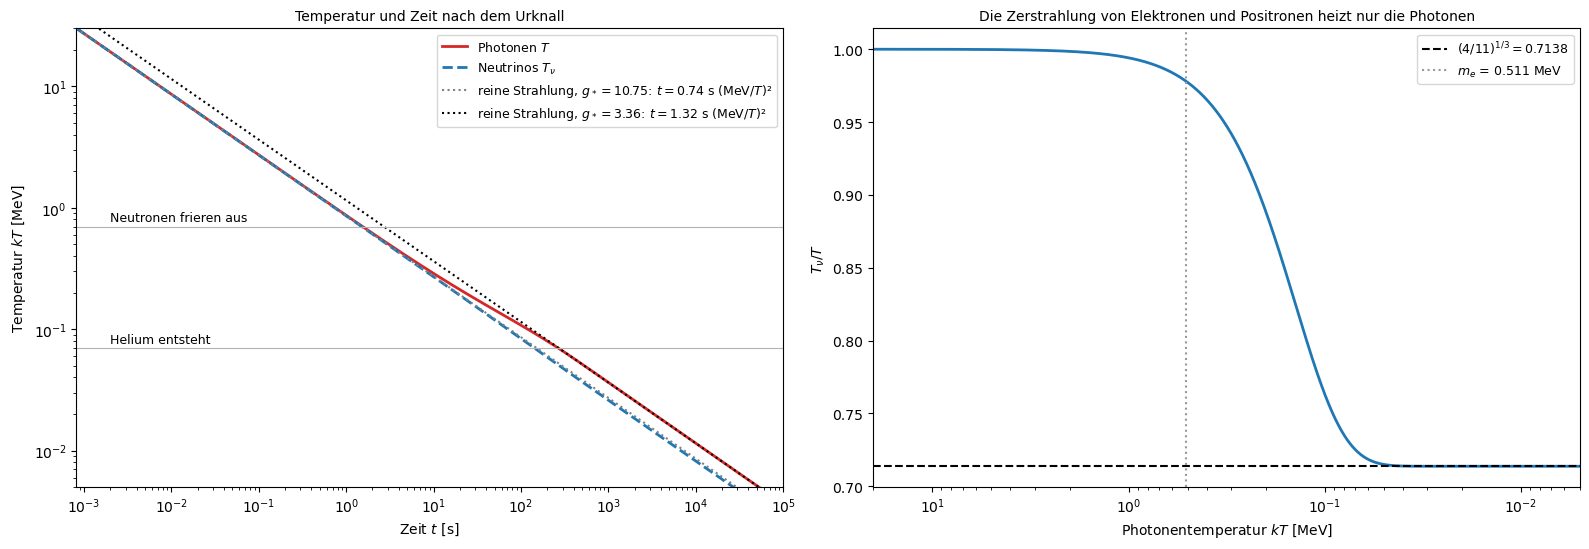

T =  1.00 MeV ( 11.60·10⁹ K): t =      0.7 s, T_ν/T = 0.9941
T =  0.50 MeV (  5.80·10⁹ K): t =      3.1 s, T_ν/T = 0.9771
T =  0.10 MeV (  1.16·10⁹ K): t =    119.2 s, T_ν/T = 0.7630
T =  0.07 MeV (  0.81·10⁹ K): t =    265.4 s, T_ν/T = 0.7253
T =  0.01 MeV (  0.12·10⁹ K): t =  13203.4 s, T_ν/T = 0.7138
am Ende T/T_ν = 1.40102, erwartet (11/4)^(1/3) = 1.40102; einfache Formel bei 0.1 MeV: 132 s


In [3]:
BG = background(3.0)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.loglog(BG["t"], BG["T"], color="C3", lw=2, label="Photonen $T$")
ax.loglog(BG["t"], BG["Tnu"], color="C0", lw=2, ls="--", label=r"Neutrinos $T_\nu$")
tt = np.geomspace(BG["t"][0], BG["t"][-1], 200)
ax.loglog(tt, np.sqrt(0.738 / tt), color="0.5", ls=":", label=r"reine Strahlung, $g_* = 10.75$: $t = 0.74$ s (MeV/$T$)²")
ax.loglog(tt, np.sqrt(1.32 / tt), color="k", ls=":", label=r"reine Strahlung, $g_* = 3.36$: $t = 1.32$ s (MeV/$T$)²")
for Tq, lab in [(0.7, "Neutronen frieren aus"), (0.07, "Helium entsteht")]:
    ax.axhline(Tq, color="0.7", lw=0.8)
    ax.text(2e-3, Tq * 1.1, lab, fontsize=9)
ax.set_xlim(BG["t"][0], 1e5)
ax.set_ylim(5e-3, 30)
ax.set_xlabel("Zeit $t$ [s]")
ax.set_ylabel("Temperatur $kT$ [MeV]")
ax.set_title("Temperatur und Zeit nach dem Urknall", fontsize=10)
ax.legend(fontsize=9)
ax2.semilogx(BG["T"], BG["Tnu"] / BG["T"], color="C0", lw=2)
ax2.axhline((4 / 11) ** (1 / 3), color="k", ls="--", label=r"$(4/11)^{1/3} = 0.7138$")
ax2.axvline(ME, color="0.6", ls=":", label=r"$m_e$ = 0.511 MeV")
ax2.set_xlim(20, 5e-3)
ax2.set_xlabel("Photonentemperatur $kT$ [MeV]")
ax2.set_ylabel(r"$T_\nu / T$")
ax2.set_title("Die Zerstrahlung von Elektronen und Positronen heizt nur die Photonen", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

t_of_T = lambda Tq: np.exp(np.interp(np.log(Tq), np.log(BG["T"][::-1]), BG["lt"][::-1]))
for Tq in [1.0, 0.5, 0.1, 0.07, 0.01]:
    i = np.argmin(abs(BG["T"] - Tq))
    print(f"T = {Tq:5.2f} MeV ({Tq / KB / 1e9:6.2f}·10⁹ K): t = {t_of_T(Tq):8.1f} s, T_ν/T = {BG['Tnu'][i] / BG['T'][i]:.4f}")
print(f"am Ende T/T_ν = {BG['T'][-1] / BG['Tnu'][-1]:.5f}, erwartet (11/4)^(1/3) = {(11 / 4) ** (1 / 3):.5f}; "
      f"einfache Formel bei 0.1 MeV: {1.32 / 0.1**2:.0f} s")

* Links die Temperatur der Photonen (rot) und der Neutrinos (blau gestrichelt) über der Zeit. Bis etwa 1 s sind beide gleich und folgen der Formel für reine Strahlung mit $g_\ast = 10.75$. Danach trennen sie sich: Die Zerstrahlung heizt die Photonen, und ihre Kurve biegt auf die Gerade für $g_\ast = 3.36$ ein. Rechts das Verhältnis $T_\nu/T$: Es fällt zwischen 0.5 und 0.05 MeV von 0.98 auf 0.7138, am steilsten um 0.15 MeV, also deutlich unter $m_e$.
* Bei 1 MeV ist das Universum 0.7 s alt, bei 0.1 MeV 119 s, bei 0.07 MeV 265 s und bei 0.01 MeV 13 200 s (3.7 Stunden). Am Ende ist $T/T_\nu$ = 1.40102, genau $(11/4)^{1/3}$: Die Entropie der Elektronen und Positronen ist vollständig bei den Photonen angekommen.
* Zur Vorhersage: jünger, 119 statt 132 s. Die einfache Formel nimmt an, dass $g_\ast = 3.36$ seit $t = 0$ galt. Vorher war $g_\ast$ größer, das Universum dehnte sich schneller aus, und es verging weniger Zeit, bis es so weit abgekühlt war.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-2"></a>

##### *2. Neutronen und Protonen*

Bei welcher Temperatur frieren die Neutronen aus, und wie viele sind dann noch übrig, wenn drei Minuten später Helium entsteht? Vorher vorhersagen: Wie groß wäre der Massenanteil des Heliums, wenn alle Neutronen vom Ausfrieren bis zur Bildung von Helium überlebten?

Der Code rechnet das Netzwerk für $\omega_b$ von Planck einmal mit dem ganzen zeitlichen Verlauf (`MAIN`, wird in den Schritten 3 und 4 weiterverwendet). Links stehen die schwachen Raten $\lambda_{n\to p}$ und $\lambda_{p\to n}$ und die Hubble-Rate über der Temperatur. Rechts steht der Anteil der Neutronen $X_n$: im Gleichgewicht $1/(1 + e^{Q/T})$, im Netzwerk (frei und in Kernen gebunden) und mit nur dem Zerfall nach dem Ausfrieren, $X_n(t) = X_n(t_f)\,e^{-(t - t_f)/\tau_n}$. Das Ausfrieren ist hier der Punkt, an dem die Summe der Raten unter $H$ fällt (Theorie, Abschnitt 2).

**Hintergrund & Fachbegriffe:**
- **Ausfrieren:** Eine Reaktion hält ein Gleichgewicht nur, solange sie häufiger stattfindet, als sich das Universum ausdehnt ($\Gamma > H$). Danach bleibt die Häufigkeit stehen, abgesehen vom Zerfall.
- **Lebensdauer des Neutrons:** $\tau_n = 878.4 \pm 0.5$ s (PDG); sie legt die Stärke aller schwachen Raten fest.

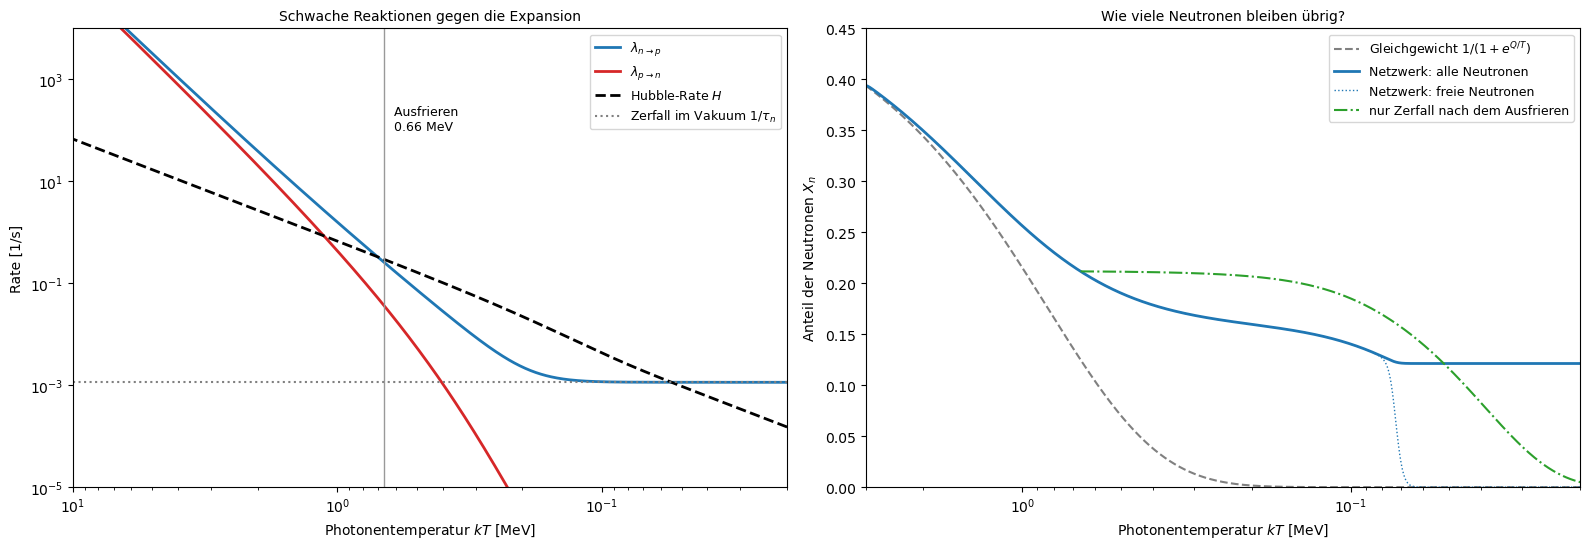

Ausfrieren (λ_np + λ_pn = H): T = 0.664 MeV, t = 1.71 s; X_n = 0.2116, im Gleichgewicht wären es 0.1248
T = 1.000 MeV: t =    0.7 s, X_n = 0.2563
T = 0.300 MeV: t =    9.1 s, X_n = 0.1686
T = 0.100 MeV: t =  119.2 s, X_n = 0.1404
T = 0.072 MeV: t =  246.8 s, X_n = 0.1225
Zerfall allein vom Ausfrieren bis zur Hälfte des Heliums: X_n = 0.1601; 2 X_n = 0.2449, Y_p (Born) = 0.2425


In [4]:
MAIN = run(PLANCK_OB[0], full=True)
xs = np.linspace(MAIN["sol"].t[0], MAIN["sol"].t[-1], 6000)
YS = MAIN["sol"].sol(xs)
TS = np.exp(np.interp(xs, BG["lt"], np.log(BG["T"])))
tS = np.exp(xs)
XN_FREE = YS[0]
XN_ALL = YS[0] + YS[2] + 2 * YS[3] + YS[4] + 2 * YS[5] + 4 * YS[6] + 3 * YS[7]   # alle Neutronen, frei und gebunden
lam_np, lam_pn = BG["W"][:, 0] / TAU_N[0], BG["W"][:, 1] / TAU_N[0]
i_f = np.argmax(lam_np + lam_pn < BG["H"])
T_F, t_F = BG["T"][i_f], BG["t"][i_f]
XN_F = np.interp(np.log(t_F), xs, XN_ALL)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.loglog(BG["T"], lam_np, color="C0", lw=2, label=r"$\lambda_{n\to p}$")
ax.loglog(BG["T"], lam_pn, color="C3", lw=2, label=r"$\lambda_{p\to n}$")
ax.loglog(BG["T"], BG["H"], color="k", lw=2, ls="--", label="Hubble-Rate $H$")
ax.axhline(1 / TAU_N[0], color="0.5", ls=":", label=r"Zerfall im Vakuum $1/\tau_n$")
ax.axvline(T_F, color="0.6", lw=1)
ax.text(T_F * 0.95, 1e2, f" Ausfrieren\n {T_F:.2f} MeV", fontsize=9)
ax.set_xlim(10, 0.02)
ax.set_ylim(1e-5, 1e4)
ax.set_xlabel("Photonentemperatur $kT$ [MeV]")
ax.set_ylabel("Rate [1/s]")
ax.set_title("Schwache Reaktionen gegen die Expansion", fontsize=10)
ax.legend(fontsize=9)
ax2.semilogx(TS, 1 / (1 + np.exp(np.minimum(Q_NP / TS, 700))), color="0.5", ls="--", label=r"Gleichgewicht $1/(1+e^{Q/T})$")
ax2.semilogx(TS, XN_ALL, color="C0", lw=2, label="Netzwerk: alle Neutronen")
ax2.semilogx(TS, XN_FREE, color="C0", lw=1, ls=":", label="Netzwerk: freie Neutronen")
late = tS > t_F
ax2.semilogx(TS[late], XN_F * np.exp(-(tS[late] - t_F) / TAU_N[0]), color="C2", ls="-.", label="nur Zerfall nach dem Ausfrieren")
ax2.set_xlim(3, 0.02)
ax2.set_ylim(0, 0.45)
ax2.set_xlabel("Photonentemperatur $kT$ [MeV]")
ax2.set_ylabel("Anteil der Neutronen $X_n$")
ax2.set_title("Wie viele Neutronen bleiben übrig?", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

T_HE = TS[np.argmax(4 * YS[5] > 0.5 * 4 * YS[5][-1])]
print(f"Ausfrieren (λ_np + λ_pn = H): T = {T_F:.3f} MeV, t = {t_F:.2f} s; X_n = {XN_F:.4f}, im Gleichgewicht wären es {1 / (1 + np.exp(Q_NP / T_F)):.4f}")
for Tq in [1.0, 0.3, 0.1, T_HE]:
    print(f"T = {Tq:.3f} MeV: t = {t_of_T(Tq):6.1f} s, X_n = {np.interp(np.log(Tq), np.log(TS[::-1]), XN_ALL[::-1]):.4f}")
print(f"Zerfall allein vom Ausfrieren bis zur Hälfte des Heliums: X_n = {XN_F * np.exp(-(t_of_T(T_HE) - t_F) / TAU_N[0]):.4f}; "
      f"2 X_n = {2 * np.interp(np.log(T_HE), np.log(TS[::-1]), XN_ALL[::-1]):.4f}, Y_p (Born) = {MAIN['born']['Yp']:.4f}")

* Links die beiden schwachen Raten und $H$ über der Temperatur. Über 1 MeV sind die Raten viel größer als $H$. $\lambda_{p\to n}$ fällt schneller, weil ein Proton die Energie $Q$ aufbringen muss. Bei 0.66 MeV (t = 1.7 s) fällt die Summe unter $H$. Unter etwa 0.1 MeV bleibt nur der Zerfall mit $1/\tau_n$. Rechts der Anteil der Neutronen: Das Gleichgewicht (grau) fällt steil, das Netzwerk folgt ihm bis etwa 2 MeV und bleibt dann darüber.
* Beim Ausfrieren nach der Definition $\lambda = H$ ist $X_n$ = 0.212; im Gleichgewicht wären es 0.125. Die Neutronen hinken also schon vorher hinterher. Danach sinkt $X_n$ weiter, und zwar schneller als durch den Zerfall allein (grün strichpunktiert, 0.160 bei 0.072 MeV), weil die schwachen Reaktionen noch bis etwa 0.2 MeV Neutronen umwandeln. Bei 0.1 MeV ist $X_n$ = 0.140, und wenn die Hälfte des Heliums steht (0.072 MeV, t = 247 s), 0.1225. Das gibt $2X_n$ = 0.245, nahe an $Y_p$ = 0.2425 in Born-Näherung. Die freien Neutronen (gepunktet) verschwinden dort fast schlagartig in Kernen.
* Zur Vorhersage: 2 × 0.212 = 0.42, fast das Doppelte der gemessenen 0.245. Der Weg von 0.212 auf 0.1225 geht etwa zur Hälfte auf den Zerfall zurück (Faktor 0.76) und zur Hälfte auf schwache Reaktionen nach dem Ausfrieren (ebenfalls 0.77). Ausfrieren ist kein scharfer Moment.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-3"></a>

##### *3. Der Engpass beim Deuterium*

Warum wartet die Nukleosynthese bis etwa 0.07 MeV, obwohl Deuterium mit 2.2 MeV gebunden ist, und wie hängt das von der Dichte der Baryonen ab? Vorher vorhersagen: Setzt die Bildung von Helium bei zehnmal mehr Baryonen früher oder später ein?

Der Code rechnet die Häufigkeit von Deuterium im Saha-Gleichgewicht (Theorie, Abschnitt 3) mit dem Anteil der Neutronen aus Schritt 2, für $\eta$ von Planck und für ein Zehntel und das Zehnfache davon. Dazu zeichnet er Deuterium und Helium-4 aus dem Netzwerk. Für jedes $\eta$ gibt er die Temperatur aus, bei der Deuterium im Gleichgewicht ein Tausendstel der freien Neutronen bindet. Grob dort beginnt die Kette zu Helium.

**Hintergrund & Fachbegriffe:**
- **Saha-Gleichgewicht:** das Gleichgewicht zwischen Bildung und Zerfall eines gebundenen Zustands bei gegebener Temperatur und Dichte; dieselbe Gleichung bestimmt die Rekombination von Wasserstoff bei 3000 K.
- **Wien-Ausläufer:** der Teil der Planck-Verteilung mit $E \gg kT$, in dem die Zahl der Photonen wie $e^{-E/kT}$ fällt. Bei $10^9$ Photonen pro Baryon reicht er weit über $B_d$ hinaus.

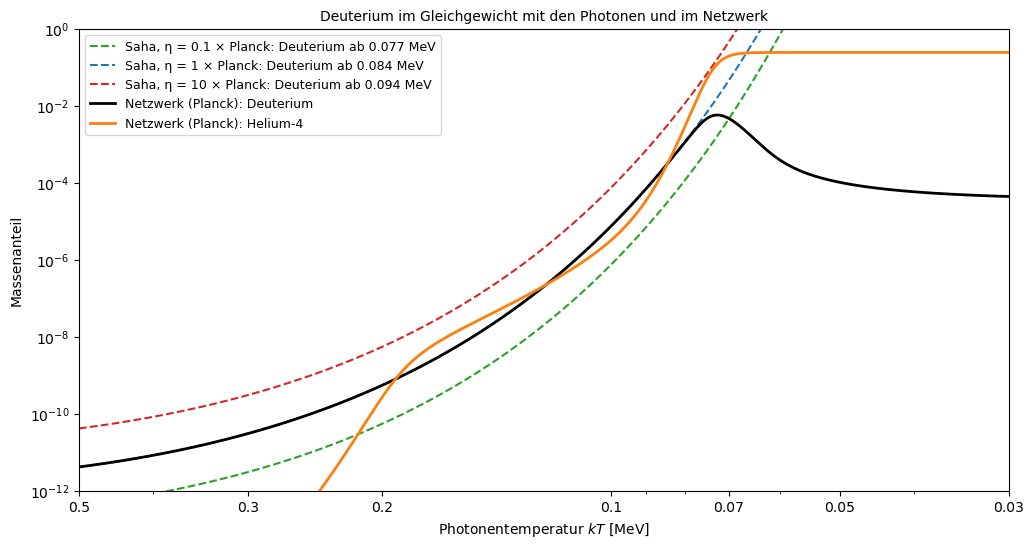

Netzwerk: Deuterium am häufigsten bei T = 0.0725 MeV (t = 246 s), Massenanteil 5.74e-03; die Hälfte des Heliums steht bei T = 0.0724 MeV (t = 247 s)
B_d/T dort: 30.7; ln(1/η) = 21.2
η =  0.1 × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = 0.0769 MeV (t = 217 s)
η =    1 × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = 0.0845 MeV (t = 176 s)
η =   10 × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = 0.0937 MeV (t = 139 s)


In [5]:
TNU0 = (4 / 11) ** (1 / 3) * T0
TT = np.geomspace(0.5, 0.03, 300)
XN_T = np.interp(np.log(TT), np.log(TS[::-1]), XN_FREE[::-1])
TNU_T = np.exp(np.interp(np.log(TT), np.log(BG["T"][::-1]), np.log(BG["Tnu"][::-1])))
fig, ax = plt.subplots(figsize=(12, 6))
T_D = {}
for f, col in [(0.1, "C2"), (1.0, "C0"), (10.0, "C3")]:
    eta = f * MAIN["eta"]
    nb = eta * NGAM0 * (TNU_T / TNU0) ** 3
    xn_eq = np.interp(np.log(TT), np.log(TS[::-1]), XN_ALL[::-1])          # Neutronen, als wären sie noch alle frei
    yd = np.array([nse(x, T, n)[2] for x, T, n in zip(xn_eq, TT, nb)])
    T_D[f] = TT[np.argmax(yd > 1e-3 * xn_eq)]
    ax.loglog(TT, 2 * yd, color=col, ls="--", label=f"Saha, η = {f:g} × Planck: Deuterium ab {T_D[f]:.3f} MeV")
ax.loglog(TS, 2 * YS[2], color="k", lw=2, label="Netzwerk (Planck): Deuterium")
ax.loglog(TS, 4 * YS[5], color="C1", lw=2, label="Netzwerk (Planck): Helium-4")
ax.set_xlim(0.5, 0.03)
ax.set_xticks([0.5, 0.3, 0.2, 0.1, 0.07, 0.05, 0.03])
ax.set_xticklabels(["0.5", "0.3", "0.2", "0.1", "0.07", "0.05", "0.03"])
ax.set_ylim(1e-12, 1)
ax.set_xlabel("Photonentemperatur $kT$ [MeV]")
ax.set_ylabel("Massenanteil")
ax.set_title("Deuterium im Gleichgewicht mit den Photonen und im Netzwerk", fontsize=10)
ax.legend(fontsize=9)
plt.show()

i_max = np.argmax(YS[2])
print(f"Netzwerk: Deuterium am häufigsten bei T = {TS[i_max]:.4f} MeV (t = {tS[i_max]:.0f} s), Massenanteil {2 * YS[2][i_max]:.2e}; "
      f"die Hälfte des Heliums steht bei T = {T_HE:.4f} MeV (t = {t_of_T(T_HE):.0f} s)")
print(f"B_d/T dort: {2.2246 / T_HE:.1f}; ln(1/η) = {np.log(1 / MAIN['eta']):.1f}")
for f in T_D:
    print(f"η = {f:4g} × Planck: Saha-Deuterium erreicht 10⁻³ der Neutronen bei T = {T_D[f]:.4f} MeV (t = {t_of_T(T_D[f]):.0f} s)")

* Der Massenanteil von Deuterium im Saha-Gleichgewicht (gestrichelt, für drei Werte von $\eta$) und im Netzwerk (schwarz), dazu Helium-4 (orange). Bis 0.1 MeV liegt das Netzwerk auf der Saha-Kurve für Planck, die darunter verdeckt ist; Deuterium macht dann nur $10^{-5}$ der Masse aus. Ab 0.08 MeV steigt es langsamer als im Gleichgewicht, weil es sofort zu Helium weiterreagiert. Sein Maximum, 0.6 % der Masse, liegt bei 0.0725 MeV (t = 246 s), genau dort, wo die Hälfte des Heliums steht.
* Mit $\eta$ von Planck bindet Deuterium im Gleichgewicht 10⁻³ der Neutronen bei 0.0845 MeV, mit zehnmal weniger Baryonen erst bei 0.0769 MeV, mit zehnmal mehr schon bei 0.0937 MeV. Der Engpass hängt nur logarithmisch an $\eta$. Wenn das Helium entsteht, ist $B_d/kT$ = 30.7. Davon erklärt $\ln(1/\eta)$ = 21.2 den größten Teil, den Rest der Faktor $(kT/m_N c^2)^{3/2}$ in der Saha-Gleichung.
* Zur Vorhersage: früher, bei 0.094 statt 0.085 MeV (t = 139 statt 176 s). Bis dahin sind weniger Neutronen zerfallen, deshalb steigt $Y_p$ leicht mit $\eta$ (Schritt 6).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-4"></a>

##### *4. Das Netzwerk: die ersten zwanzig Minuten*

Wann entstehen die einzelnen Kerne, und was bleibt am Ende übrig, wenn man $\omega_b$ von Planck einsetzt? Vorher vorhersagen: Welcher Kern erreicht seinen höchsten Anteil, bevor er wieder verbrennt?

Der Code zeichnet die Massenanteile $X_i = A_i Y_i$ der acht Kerne aus dem Lauf von Schritt 2 über der Zeit, mit der Temperatur auf der oberen Achse. Er gibt die Endwerte in Born-Näherung und mit den Korrekturen aus (Theorie, Abschnitt 4). ⁷Be wird zu ⁷Li gezählt, Tritium zu ³He, denn beide zerfallen später. Zum Vergleich stehen die Werte von PRIMAT bei $\omega_b = 0.02242$ (Pitrou et al. 2021); genau verglichen wird in Schritt 5.

**Hintergrund & Fachbegriffe:**
- **Tritium:** ³H, zerfällt mit 12.3 Jahren Halbwertszeit zu ³He.
- **⁷Be:** zerfällt durch Elektroneneinfang mit 53 Tagen Halbwertszeit zu ⁷Li, sobald es Elektronen einfangen kann; bei $\omega_b$ von Planck entsteht der größte Teil des Lithiums als ⁷Be.

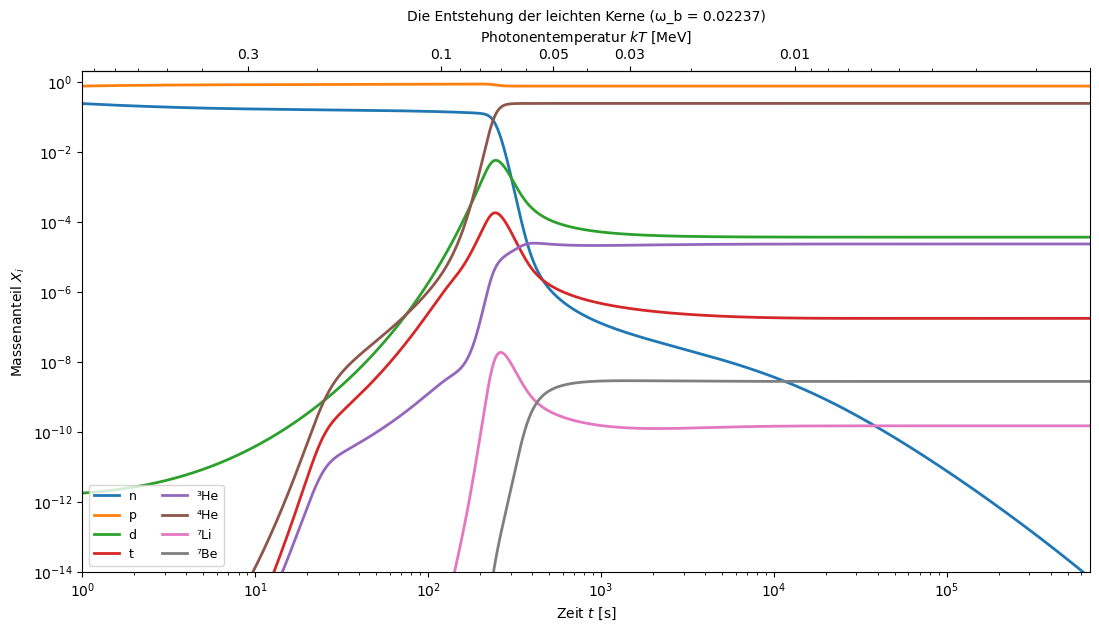

d   : höchster Massenanteil 5.74e-03 bei t =    246 s, am Ende 3.65e-05
t   : höchster Massenanteil 1.82e-04 bei t =    244 s, am Ende 1.75e-07
³He : höchster Massenanteil 2.46e-05 bei t =    412 s, am Ende 2.33e-05
⁷Li : höchster Massenanteil 1.86e-08 bei t =    263 s, am Ende 1.49e-10
⁷Be : höchster Massenanteil 2.89e-09 bei t =   1415 s, am Ende 2.76e-09
Born:       Y_p = 0.24245, D/H = 2.4108e-05, ³He/H = 1.0350e-05, ⁷Li/H = 5.483e-10
korrigiert: Y_p = 0.24692, D/H = 2.4467e-05, ³He/H = 1.0398e-05, ⁷Li/H = 5.517e-10; ⁷Li stammt zu 95% aus ⁷Be
PRIMAT (Pitrou et al. 2021, ω_b = 0.02242, τ_n = 879.4 s): Y_p = 0.24721, D/H = 2.439e-05, ³He/H = 1.039e-05, ⁷Li/H = 5.464e-10


In [6]:
fig, ax = plt.subplots(figsize=(13, 6.5))
A = [1, 1, 2, 3, 3, 4, 7, 7]
NAMES = ["n", "p", "d", "t", "³He", "⁴He", "⁷Li", "⁷Be"]
for i, (a, lab) in enumerate(zip(A, NAMES)):
    ax.loglog(tS, np.maximum(a * YS[i], 1e-30), lw=2, color=f"C{i}", label=lab)
ax.set_xlim(1, tS[-1])
ax.set_ylim(1e-14, 2)
ax.set_xlabel("Zeit $t$ [s]")
ax.set_ylabel("Massenanteil $X_i$")
ax.set_title(f"Die Entstehung der leichten Kerne (ω_b = {PLANCK_OB[0]})", fontsize=10)
ax.legend(fontsize=9, ncol=2, loc="lower left")
top = ax.secondary_xaxis("top", functions=(lambda t: np.interp(np.log(np.maximum(t, 1e-3)), BG["lt"], BG["T"]),
                                            lambda T: np.exp(np.interp(-np.log(np.maximum(T, 1e-6)), -np.log(BG["T"]), BG["lt"]))))
top.set_xticks([1.0, 0.3, 0.1, 0.05, 0.03, 0.01])
top.set_xticklabels(["1", "0.3", "0.1", "0.05", "0.03", "0.01"])
top.set_xlabel("Photonentemperatur $kT$ [MeV]")
plt.show()

for i in [2, 3, 4, 6, 7]:
    lab = NAMES[i]
    j = np.argmax(YS[i])
    print(f"{lab:4s}: höchster Massenanteil {A[i] * YS[i][j]:.2e} bei t = {tS[j]:6.0f} s, am Ende {A[i] * YS[i][-1]:.2e}")
b, c = MAIN["born"], MAIN
print(f"Born:       Y_p = {b['Yp']:.5f}, D/H = {b['DH']:.4e}, ³He/H = {b['He3H']:.4e}, ⁷Li/H = {b['Li7H']:.3e}")
print(f"korrigiert: Y_p = {c['Yp']:.5f}, D/H = {c['DH']:.4e}, ³He/H = {c['He3H']:.4e}, ⁷Li/H = {c['Li7H']:.3e}; "
      f"⁷Li stammt zu {YS[7][-1] / (YS[6][-1] + YS[7][-1]):.0%} aus ⁷Be")
print("PRIMAT (Pitrou et al. 2021, ω_b = 0.02242, τ_n = 879.4 s): Y_p = 0.24721, D/H = 2.439e-05, ³He/H = 1.039e-05, ⁷Li/H = 5.464e-10")

* Die Massenanteile der acht Kerne über der Zeit. Bis etwa 200 s ändern sich nur Neutronen und Protonen; die Kerne stehen im Gleichgewicht bei winzigen Werten. Zwischen 200 und 300 s läuft fast alles ab: Die Neutronen verschwinden, Helium-4 springt auf 0.24, Deuterium und Tritium erreichen ihr Maximum und verbrennen. Nach etwa 1000 s ändert sich nur noch der Zerfall der letzten freien Neutronen; Tritium und ⁷Be zerfallen viel später.
* Endwerte bei $\omega_b$ = 0.02237: in Born-Näherung $Y_p$ = 0.24245 und D/H = 2.411·10⁻⁵. Mit den Korrekturen sind es $Y_p$ = 0.2469, D/H = 2.447·10⁻⁵, ³He/H = 1.040·10⁻⁵ und ⁷Li/H = 5.52·10⁻¹⁰. ⁷Li entsteht zu 95 % als ⁷Be. PRIMAT gibt bei leicht anderem $\omega_b$ und $\tau_n$ fast dasselbe; den genauen Vergleich zeigt Schritt 5.
* Zur Vorhersage: Deuterium mit 0.57 % der Masse bei 246 s (am Ende 0.0037 %), ebenso Tritium (0.018 %) und ⁷Li (1.9·10⁻⁸ bei 263 s, am Ende 1.5·10⁻¹⁰). ³He und ⁷Be bleiben fast auf ihrem Höchstwert.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-5"></a>

##### *5. Prüfung gegen einen vollständigen Code*

Wie gut stimmt das eigene Netzwerk mit PRIMAT und PRyMordial überein, über welchen Bereich von $\omega_b$ und $N_\text{eff}$, und reichen die festen Korrekturen zur Born-Näherung? Vorher vorhersagen: Wie groß ist die Korrektur zur Born-Näherung in $Y_p$, verglichen mit dem Messfehler von 0.0034?

Der Code rechnet drei Vergleiche:
- **Born gegen Born:** mit den Einstellungen von Pitrou et al. (2018, Tabelle V, Zeile „Born“): $\omega_b = 0.02225$, $\tau_n = 879.5$ s, $N_\text{eff} = 3$.
- **Vollständig gegen vollständig:** mit Korrekturen gegen PRIMAT 2021 (Tabelle 2: $\omega_b = 0.02242$, $\tau_n = 879.4$ s).
- **Gegen PRyMordial:** mit den Raten von NACRE II gegen die Ergebnistabelle über $\omega_b$ = 0.020 bis 0.024 und $\Delta N_\text{eff} = -1, 0, +1$.

PRyMordial nimmt $\tau_n = 878.4$ s wie dieses Notebook.

**Hintergrund & Fachbegriffe:**
- **Unvollständige Entkopplung:** Die Neutrinos sind bei der Zerstrahlung noch nicht ganz entkoppelt und bekommen etwas Energie ab; daher $N_\text{eff} = 3.044$ statt 3.
- **Ergebnistabelle:** PRyMordial gibt Mittelwerte aus Monte-Carlo-Läufen über die Unsicherheiten der Raten; die Einträge schwanken deshalb um einige Promille von Zeile zu Zeile.

        eigen Born  Pitrou 2018 Born     Abw. | eigen korr.  Pitrou 2021     Abw.
Yp         0.24262           0.24262 +0.00000 |     0.24715      0.24721 -0.00006
DH         2.43349           2.42300   +0.43% |     2.43885      2.43900   -0.01%
He3H       1.03840           1.06900   -2.86% |     1.03867      1.03900   -0.03%
Li7H       5.42547           5.63500   -3.72% |     5.54565      5.46400   +1.49%


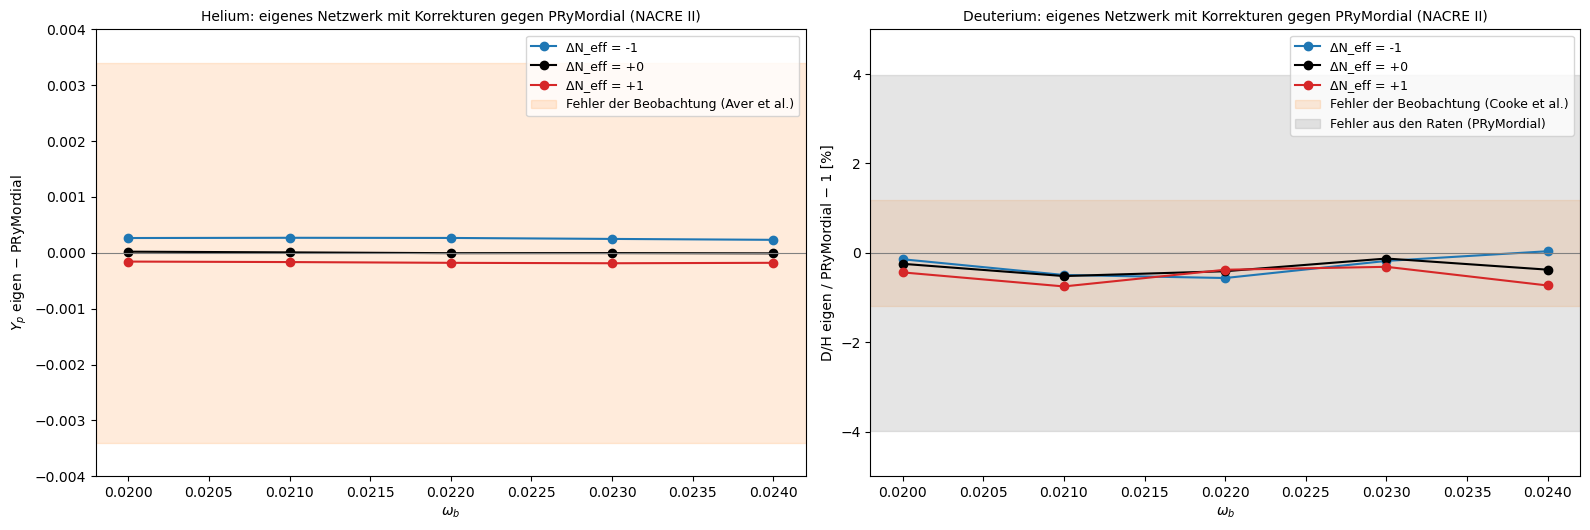

ΔN_eff = -1: Y_p +0.00023 bis +0.00027, D/H -0.56 % bis +0.04 %
ΔN_eff = +0: Y_p -0.00001 bis +0.00002, D/H -0.52 % bis -0.13 %
ΔN_eff = +1: Y_p -0.00019 bis -0.00016, D/H -0.75 % bis -0.31 %


In [7]:
r_born = run(0.02225, neff=3.0, tau_n=879.5)["born"]
r_21 = run(0.02242, tau_n=879.4)
print(f"{'':6s} {'eigen Born':>11s} {'Pitrou 2018 Born':>17s} {'Abw.':>8s} | {'eigen korr.':>11s} {'Pitrou 2021':>12s} {'Abw.':>8s}")
for k, f in [("Yp", 1), ("DH", 1e5), ("He3H", 1e5), ("Li7H", 1e10)]:
    d1 = r_born[k] - PITROU_BORN[k] if k == "Yp" else r_born[k] / PITROU_BORN[k] - 1
    d2 = r_21[k] - PITROU_21[k] if k == "Yp" else r_21[k] / PITROU_21[k] - 1
    fmt = (lambda d: f"{d:+8.5f}") if k == "Yp" else (lambda d: f"{100 * d:+7.2f}%")
    print(f"{k:6s} {f * r_born[k]:11.5f} {f * PITROU_BORN[k]:17.5f} {fmt(d1)} | {f * r_21[k]:11.5f} {f * PITROU_21[k]:12.5f} {fmt(d2)}")

OB_V = [0.020, 0.021, 0.022, 0.023, 0.024]
VAL = {}
for dn in [-1.0, 0.0, 1.0]:
    for ob in OB_V:
        m = np.isclose(PRYM_TAB[:, 0], ob) & np.isclose(PRYM_TAB[:, 2], dn)
        r = run(ob, rates=NACRE, neff=3.0 + dn)
        VAL[(dn, ob)] = (r["Yp"] - PRYM_TAB[m][0, 4], r["DH"] / PRYM_TAB[m][0, 6] - 1, PRYM_TAB[m][0, 7] / PRYM_TAB[m][0, 6])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.4))
for dn, col in [(-1.0, "C0"), (0.0, "k"), (1.0, "C3")]:
    ax.plot(OB_V, [VAL[(dn, o)][0] for o in OB_V], "o-", color=col, label=f"ΔN_eff = {dn:+.0f}")
    ax2.plot(OB_V, [100 * VAL[(dn, o)][1] for o in OB_V], "o-", color=col, label=f"ΔN_eff = {dn:+.0f}")
ax.axhspan(-YP_OBS[1], YP_OBS[1], color="C1", alpha=0.15, label="Fehler der Beobachtung (Aver et al.)")
ax2.axhspan(-100 * DH_OBS[1] / DH_OBS[0], 100 * DH_OBS[1] / DH_OBS[0], color="C1", alpha=0.15, label="Fehler der Beobachtung (Cooke et al.)")
ax2.axhspan(-100 * np.median([v[2] for v in VAL.values()]), 100 * np.median([v[2] for v in VAL.values()]), color="0.5", alpha=0.2,
            label="Fehler aus den Raten (PRyMordial)")
for a, lab in [(ax, r"$Y_p$ eigen − PRyMordial"), (ax2, "D/H eigen / PRyMordial − 1 [%]")]:
    a.axhline(0, color="0.5", lw=0.8)
    a.set_xlabel(r"$\omega_b$")
    a.set_ylabel(lab)
    a.legend(fontsize=9)
ax.set_ylim(-0.004, 0.004)
ax2.set_ylim(-5, 5)
ax.set_title("Helium: eigenes Netzwerk mit Korrekturen gegen PRyMordial (NACRE II)", fontsize=10)
ax2.set_title("Deuterium: eigenes Netzwerk mit Korrekturen gegen PRyMordial (NACRE II)", fontsize=10)
plt.tight_layout()
plt.show()
for dn in [-1.0, 0.0, 1.0]:
    v = np.array([VAL[(dn, o)][:2] for o in OB_V])
    print(f"ΔN_eff = {dn:+.0f}: Y_p {v[:, 0].min():+.5f} bis {v[:, 0].max():+.5f}, D/H {100 * v[:, 1].min():+.2f} % bis {100 * v[:, 1].max():+.2f} %")

* Die Tabelle oben: Mit den Einstellungen von Pitrou et al. (2018) trifft das Netzwerk $Y_p$ in Born-Näherung auf alle fünf Stellen (0.24262) und D/H auf 0.4 %. ³He/H und ⁷Li/H liegen 3 bis 4 % darunter. Die Tabellen von PRyMordial entsprechen offenbar dem Stand von PRIMAT 2021, denn dort ist ³He/H um 3 % kleiner als 2018. Gegen PRIMAT 2021 mit Korrekturen stimmen $Y_p$ auf 0.00006, D/H und ³He/H auf 0.03 % und ⁷Li/H auf 1.5 %.
* Die Plots zeigen das Netzwerk mit Korrekturen minus PRyMordial, mit den Raten von NACRE II, links $Y_p$ und rechts D/H. Bei $\Delta N_\text{eff} = 0$ trifft $Y_p$ auf ±0.00002. Bei −1 und +1 liegt es 0.0002 bis 0.0003 daneben, weil die Korrekturen für $N_\text{eff} = 3$ bestimmt sind. D/H liegt 0.1 bis 0.75 % unter PRyMordial; die Zacken kommen vom Monte Carlo der Tabelle. Alles liegt weit innerhalb der Messfehler (orange) und des Fehlers, den PRyMordial für die Raten angibt (grau, 4 %).
* Zur Vorhersage: +0.0045, das 1.3-Fache des Messfehlers. Ohne die Korrekturen wäre $Y_p$ für Aussagen über $N_\text{eff}$ unbrauchbar. Bei D/H sind es +1.5 %, etwa so viel wie der Messfehler.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-6"></a>

##### *6. Das Schramm-Diagramm*

Bei welcher Baryonendichte passen die beobachteten Häufigkeiten von Helium, Deuterium, Helium-3 und Lithium, und passen alle bei derselben? Vorher vorhersagen: Welche Häufigkeit ändert sich am wenigsten mit $\eta$, und welche ist kein monotoner Verlauf?

Der Code rechnet das Netzwerk mit PRIMAT für 16 Werte von $\eta_{10}$ zwischen 1 und 10. Er zeichnet $Y_p$, D/H und ³He/H sowie ⁷Li/H über $\eta_{10}$ (oben $\omega_b$) mit den Beobachtungen als Bänder und dem Wert von Planck als senkrechtem Band. Ausgegeben wird, wo jede Kurve die Mitte ihrer Beobachtung kreuzt.

**Hintergrund & Fachbegriffe:**
- **Schramm-Diagramm:** die Häufigkeiten der leichten Kerne über der Baryonendichte, benannt nach David Schramm, der die Nukleosynthese als Test der Kosmologie bekannt machte.
- **Die Senke beim Lithium:** Bei kleinem $\eta$ entsteht ⁷Li direkt über t(α,γ)⁷Li und wird von Protonen zerstört; bei großem $\eta$ entsteht es als ⁷Be über ³He(α,γ)⁷Be. Dazwischen liegt ein Minimum.

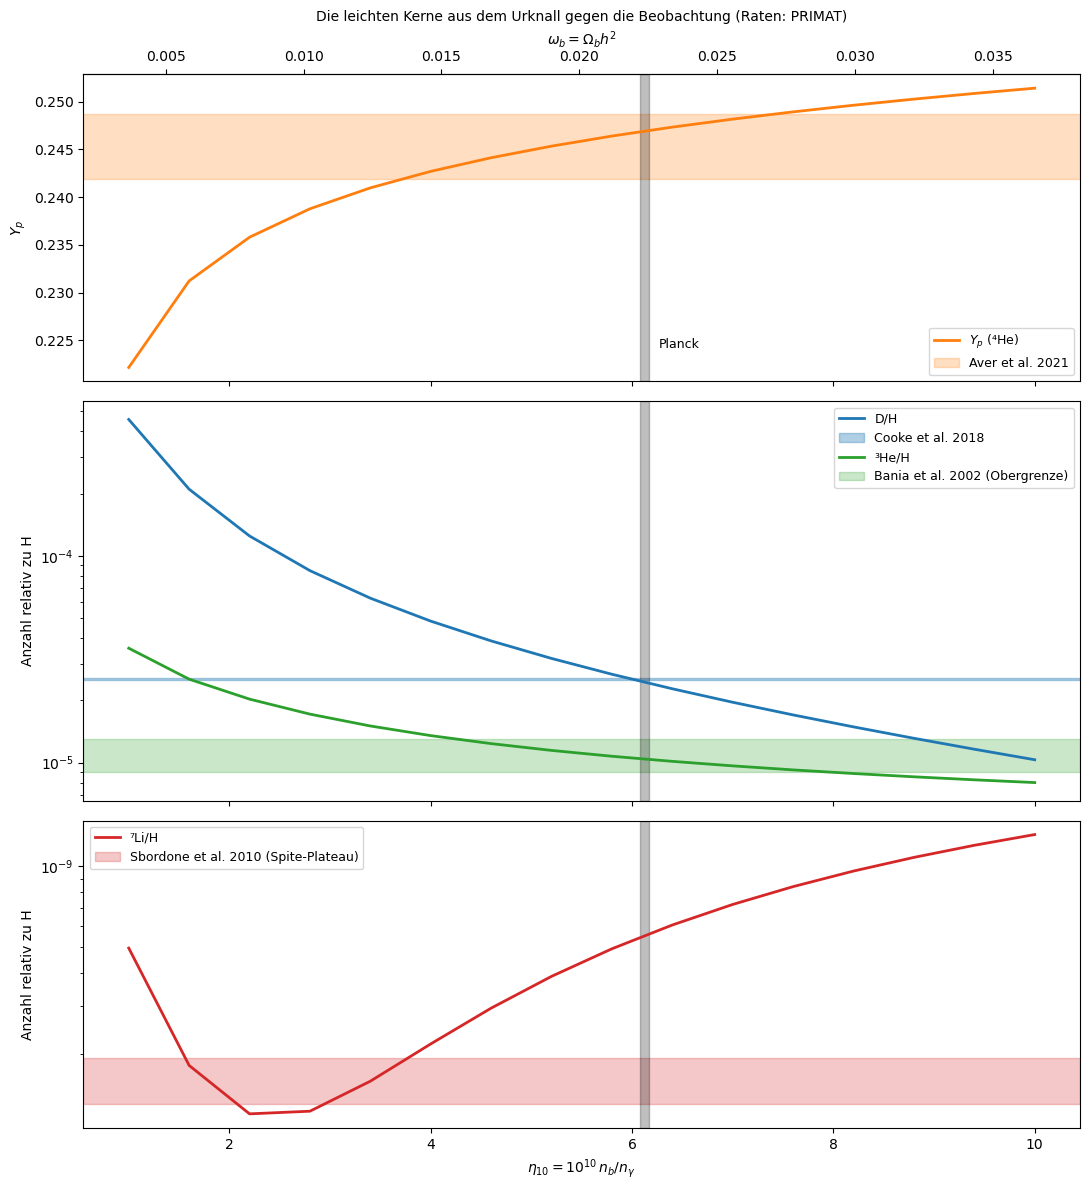

Y_p   : Beobachtung getroffen bei η₁₀ = 5.18 (ω_b = 0.0189); Spanne über η₁₀ = 1 bis 10: 0.222 bis 0.251
D/H   : Beobachtung getroffen bei η₁₀ = 6.01 (ω_b = 0.0220); Spanne über η₁₀ = 1 bis 10: 1.03e-05 bis 0.000456
³He/H : Beobachtung getroffen bei η₁₀ = 5.57 (ω_b = 0.0204); Spanne über η₁₀ = 1 bis 10: 8.01e-06 bis 3.57e-05
⁷Li/H : Beobachtung getroffen bei η₁₀ = 1.79 (ω_b = 0.0066), 3.40 (ω_b = 0.0124); Spanne über η₁₀ = 1 bis 10: 1.19e-10 bis 1.31e-09
Planck: η₁₀ = 6.124


In [8]:
ETA10 = np.linspace(1, 10, 16)
OB_S = ETA10 / (1e10 * omega_to_eta(1.0))
SCH = [run(o) for o in OB_S]
SY = {k: np.array([s[k] for s in SCH]) for k in ("Yp", "DH", "He3H", "Li7H")}
fig, axs = plt.subplots(3, 1, figsize=(11, 12), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.3, 1]))
eta_pl = 1e10 * omega_to_eta(np.array([PLANCK_OB[0] - PLANCK_OB[1], PLANCK_OB[0] + PLANCK_OB[1]]))
axs[0].plot(ETA10, SY["Yp"], color="C1", lw=2, label=r"$Y_p$ (⁴He)")
axs[0].axhspan(YP_OBS[0] - YP_OBS[1], YP_OBS[0] + YP_OBS[1], color="C1", alpha=0.25, label="Aver et al. 2021")
axs[0].set_ylabel(r"$Y_p$")
axs[1].semilogy(ETA10, SY["DH"], color="C0", lw=2, label="D/H")
axs[1].axhspan(DH_OBS[0] - DH_OBS[1], DH_OBS[0] + DH_OBS[1], color="C0", alpha=0.35, label="Cooke et al. 2018")
axs[1].semilogy(ETA10, SY["He3H"], color="C2", lw=2, label="³He/H")
axs[1].axhspan(HE3_OBS[0] - HE3_OBS[1], HE3_OBS[0] + HE3_OBS[1], color="C2", alpha=0.25, label="Bania et al. 2002 (Obergrenze)")
axs[1].set_ylabel("Anzahl relativ zu H")
axs[2].semilogy(ETA10, SY["Li7H"], color="C3", lw=2, label="⁷Li/H")
axs[2].axhspan(LI_OBS[0] * np.exp(-LI_OBS[1]), LI_OBS[0] * np.exp(LI_OBS[1]), color="C3", alpha=0.25, label="Sbordone et al. 2010 (Spite-Plateau)")
axs[2].set_ylabel("Anzahl relativ zu H")
axs[2].set_xlabel(r"$\eta_{10} = 10^{10}\, n_b / n_\gamma$")
for a in axs:
    a.axvspan(*eta_pl, color="k", alpha=0.25)
    a.legend(fontsize=9, loc="best")
axs[0].text(eta_pl[1] + 0.1, SY["Yp"].min() + 0.002, "Planck", fontsize=9)
top = axs[0].secondary_xaxis("top", functions=(lambda e: e / (1e10 * omega_to_eta(1.0)), lambda o: o * 1e10 * omega_to_eta(1.0)))
top.set_xlabel(r"$\omega_b = \Omega_b h^2$")
axs[0].set_title("Die leichten Kerne aus dem Urknall gegen die Beobachtung (Raten: PRIMAT)", fontsize=10)
plt.tight_layout()
plt.show()

for k, (v, lab) in {"Yp": (YP_OBS[0], "Y_p"), "DH": (DH_OBS[0], "D/H"), "He3H": (HE3_OBS[0], "³He/H"), "Li7H": (LI_OBS[0], "⁷Li/H")}.items():
    y = SY[k] - v if k == "Yp" else np.log(SY[k] / v)
    cross = [ETA10[i] - y[i] * (ETA10[i + 1] - ETA10[i]) / (y[i + 1] - y[i]) for i in range(len(y) - 1) if y[i] * y[i + 1] < 0]
    print(f"{lab:6s}: Beobachtung getroffen bei η₁₀ = " + (", ".join(f"{c:.2f} (ω_b = {c / (1e10 * omega_to_eta(1.0)):.4f})" for c in cross) or "nirgends")
          + f"; Spanne über η₁₀ = 1 bis 10: {SY[k].min():.3g} bis {SY[k].max():.3g}")
print(f"Planck: η₁₀ = {1e10 * omega_to_eta(PLANCK_OB[0]):.3f}")

* Drei Felder über $\eta_{10}$ (oben $\omega_b$): oben $Y_p$, in der Mitte D/H und ³He/H, unten ⁷Li/H. Die Bänder sind die Beobachtungen, grau ist Planck. Über eine ganze Größenordnung von $\eta$ ändert sich $Y_p$ nur von 0.222 auf 0.251. D/H fällt in derselben Spanne von 4.6·10⁻⁴ auf 1.0·10⁻⁵.
* D/H trifft die Messung bei $\eta_{10}$ = 6.01 ($\omega_b$ = 0.0220), nahe Planck (6.12). $Y_p$ trifft die Mitte seiner Messung bei 5.18. Wegen der flachen Kurve heißt das wenig: Das Band der Messung überdeckt $\eta_{10}$ von etwa 3.5 bis 7.6. ³He/H passt bei 5.57, innerhalb seines breiten Bandes. ⁷Li/H trifft das Spite-Plateau nur bei $\eta_{10}$ = 1.8 oder 3.4, weit weg von allen anderen; bei Planck liegt es 3.5-mal darüber.
* Zur Vorhersage: $Y_p$ ändert sich am wenigsten (13 % über den ganzen Bereich). ⁷Li/H hat eine Senke bei $\eta_{10} \approx 2.5$. Links davon entsteht es direkt als ⁷Li, rechts als ⁷Be.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-7"></a>

##### *7. Welche Reaktionen den Fehler bestimmen*

Wie genau sagt die Nukleosynthese D/H, $Y_p$ und ⁷Li/H voraus, wenn man nur die Unsicherheiten der Kernphysik betrachtet, und welche Reaktionen tragen am meisten bei? Vorher vorhersagen: Welche Reaktion hat den größten Hebel auf Deuterium?

Der Code erhöht jede der zwölf Raten um ihren 1σ-Fehlerfaktor (abhängig von der Temperatur, wie tabelliert) und rechnet neu. Die Änderung von $\ln$(D/H), $\ln$(⁷Li/H) und $Y_p$ ist der Beitrag dieser Reaktion zum Fehler. Dazu kommt $\tau_n$ um 0.5 s. Die Summe der Quadrate gibt den Fehler aus der Kernphysik. Ein Monte Carlo mit 60 Läufen prüft das: Alle Raten werden zugleich lognormal gezogen, dazu $\tau_n$ normal. Außerdem gibt der Code die **Empfindlichkeiten** $\partial \ln(\text{D/H}) / \partial \ln(\text{Rate})$ aus, aus einer Änderung um 5 %.

**Hintergrund & Fachbegriffe:**
- **Lineare Fehlerfortpflanzung:** Bei kleinen, unabhängigen Fehlern addieren sich die Beiträge quadratisch; das gilt, solange das Ergebnis in jedem Faktor fast linear ist.
- **Empfindlichkeit:** der Exponent $s$ in $\text{D/H} \propto \text{Rate}^{s}$; $s = -0.5$ heißt, 2 % mehr Rate geben 1 % weniger Deuterium.

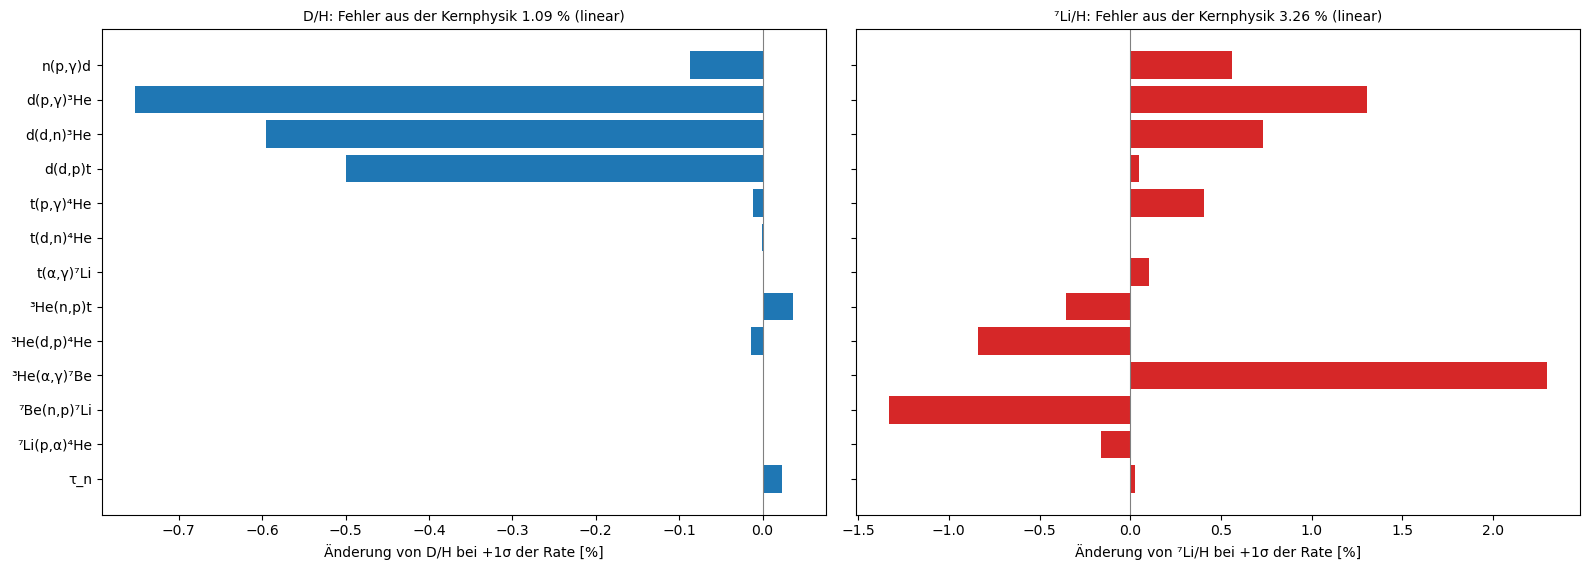

d(p,γ)³He   : D/H -0.75 % (1σ), Empfindlichkeit -0.358
d(d,n)³He   : D/H -0.60 % (1σ), Empfindlichkeit -0.549
d(d,p)t     : D/H -0.50 % (1σ), Empfindlichkeit -0.462
n(p,γ)d     : D/H -0.09 % (1σ), Empfindlichkeit -0.193
³He(n,p)t   : D/H +0.04 % (1σ), Empfindlichkeit +0.025
Fehler aus der Kernphysik, linear: D/H 1.09 %, ³He/H 1.25 %, ⁷Li/H 3.26 %, Y_p 0.00010 (davon τ_n 0.00010)
Monte Carlo (60): D/H 1.07 %, ⁷Li/H 3.19 %, Y_p 0.00008


In [9]:
OB_REF = PLANCK_OB[0]
base = MAIN
CONTR, SENS = {}, {}
for k, (name, _, _) in enumerate(REAC):
    fac = np.ones((NR, len(LX)))
    fac[k] = np.exp(PRIMAT[1][k])
    r = run(OB_REF, fac=fac)
    CONTR[name] = dict(DH=np.log(r["DH"] / base["DH"]), Li7H=np.log(r["Li7H"] / base["Li7H"]), Yp=r["Yp"] - base["Yp"], He3H=np.log(r["He3H"] / base["He3H"]))
    fac[k] = 1.05
    SENS[name] = np.log(run(OB_REF, fac=fac)["DH"] / base["DH"]) / np.log(1.05)
r = run(OB_REF, tau_n=TAU_N[0] + TAU_N[1])
CONTR["τ_n"] = dict(DH=np.log(r["DH"] / base["DH"]), Li7H=np.log(r["Li7H"] / base["Li7H"]), Yp=r["Yp"] - base["Yp"], He3H=np.log(r["He3H"] / base["He3H"]))
NUC_ERR = {q: np.sqrt(sum(v[q] ** 2 for v in CONTR.values())) for q in ("DH", "Li7H", "Yp", "He3H")}

rng = np.random.default_rng(7)
MC = []
for _ in range(60):
    z = rng.standard_normal(NR)
    m = run(OB_REF, fac=np.exp(z[:, None] * PRIMAT[1]), tau_n=TAU_N[0] + TAU_N[1] * rng.standard_normal())
    MC.append((np.log(m["DH"]), np.log(m["Li7H"]), m["Yp"]))
MC = np.array(MC)

names = list(CONTR)
lab = [LABEL.get(n, n) for n in names]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.8), sharey=True)
y = np.arange(len(names))
ax.barh(y, [100 * CONTR[n]["DH"] for n in names], color="C0")
ax2.barh(y, [100 * CONTR[n]["Li7H"] for n in names], color="C3")
ax.set_yticks(y)
ax.set_yticklabels(lab)
ax.invert_yaxis()
for a, q, t in [(ax, "DH", "D/H"), (ax2, "Li7H", "⁷Li/H")]:
    a.axvline(0, color="0.5", lw=0.8)
    a.set_xlabel(f"Änderung von {t} bei +1σ der Rate [%]")
    a.set_title(f"{t}: Fehler aus der Kernphysik {100 * NUC_ERR[q]:.2f} % (linear)", fontsize=10)
plt.tight_layout()
plt.show()

for n in sorted(names, key=lambda n: -abs(CONTR[n]["DH"]))[:5]:
    print(f"{LABEL.get(n, n):12s}: D/H {100 * CONTR[n]['DH']:+.2f} % (1σ)" + (f", Empfindlichkeit {SENS[n]:+.3f}" if n in SENS else ""))
print(f"Fehler aus der Kernphysik, linear: D/H {100 * NUC_ERR['DH']:.2f} %, ³He/H {100 * NUC_ERR['He3H']:.2f} %, ⁷Li/H {100 * NUC_ERR['Li7H']:.2f} %, "
      f"Y_p {NUC_ERR['Yp']:.5f} (davon τ_n {abs(CONTR['τ_n']['Yp']):.5f})")
print(f"Monte Carlo (60): D/H {100 * MC[:, 0].std():.2f} %, ⁷Li/H {100 * MC[:, 1].std():.2f} %, Y_p {MC[:, 2].std():.5f}")

* Die Änderung von D/H (links) und ⁷Li/H (rechts), wenn eine Rate um ihren 1σ-Faktor steigt. Für D/H zählen drei Reaktionen: d(p,γ)³He (−0.75 %), d(d,n)³He (−0.60 %) und d(d,p)t (−0.50 %). n(p,γ)d ist auf 0.4 % bekannt und trägt kaum bei. Beim Lithium führen ³He(α,γ)⁷Be (+2.3 %) und ⁷Be(n,p)⁷Li (−1.3 %).
* Der Fehler aus der Kernphysik, linear summiert, ist für D/H 1.09 %, für ³He/H 1.25 %, für ⁷Li/H 3.26 % und für $Y_p$ 0.0001 (fast nur $\tau_n$). Das Monte Carlo mit 60 Läufen bestätigt das (1.07 %, 3.19 %, 0.00008). Bei D/H ist der Fehler aus der Kernphysik damit fast so groß wie der der Messung (1.19 %).
* Zur Vorhersage: d(d,n)³He hat mit −0.55 die größte Empfindlichkeit, vor d(d,p)t (−0.46) und d(p,γ)³He (−0.36). Den größten Beitrag zum Fehler liefert trotzdem d(p,γ)³He, weil seine Rate doppelt so unsicher ist (2.2 % statt 1.1 %).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-8"></a>

##### *8. Die Baryonendichte aus Deuterium*

Welches $\omega_b$ folgt aus D/H = (2.527 ± 0.030)·10⁻⁵, und wie weit liegt es vom Wert der Hintergrundstrahlung? Vorher vorhersagen: Liegt das Ergebnis über oder unter $\omega_b$ von Planck, wenn PRIMAT bei Planck D/H = 2.44·10⁻⁵ vorhersagt?

Der Code rechnet D/H mit PRIMAT auf einem feinen Gitter von $\omega_b$ = 0.0205 bis 0.0235. Er passt $\ln(\text{D/H})$ gegen $\ln\omega_b$ mit einer kubischen Spline an und sucht das $\omega_b$, bei dem die Kurve die Beobachtung trifft. Der Fehler hat zwei Teile: die Messung (1.2 % in D/H) und die Kernphysik aus Schritt 7. Beide werden über die Steigung in einen Fehler von $\omega_b$ übersetzt. Links stehen Kurve, Fehlerband und Messung, rechts die Verteilungen von $\omega_b$ neben der von Planck.

**Hintergrund & Fachbegriffe:**
- **Inversion:** Statt D/H aus $\omega_b$ vorherzusagen, sucht man $\omega_b$ zu einem gemessenen D/H. Weil D/H ∝ $\omega_b^{-1.6}$, wird ein Fehler in D/H durch 1.6 geteilt.
- **Abstand in σ:** die Differenz zweier Werte geteilt durch die Wurzel aus der Summe ihrer Varianzen; unter 2σ gilt meist als verträglich.

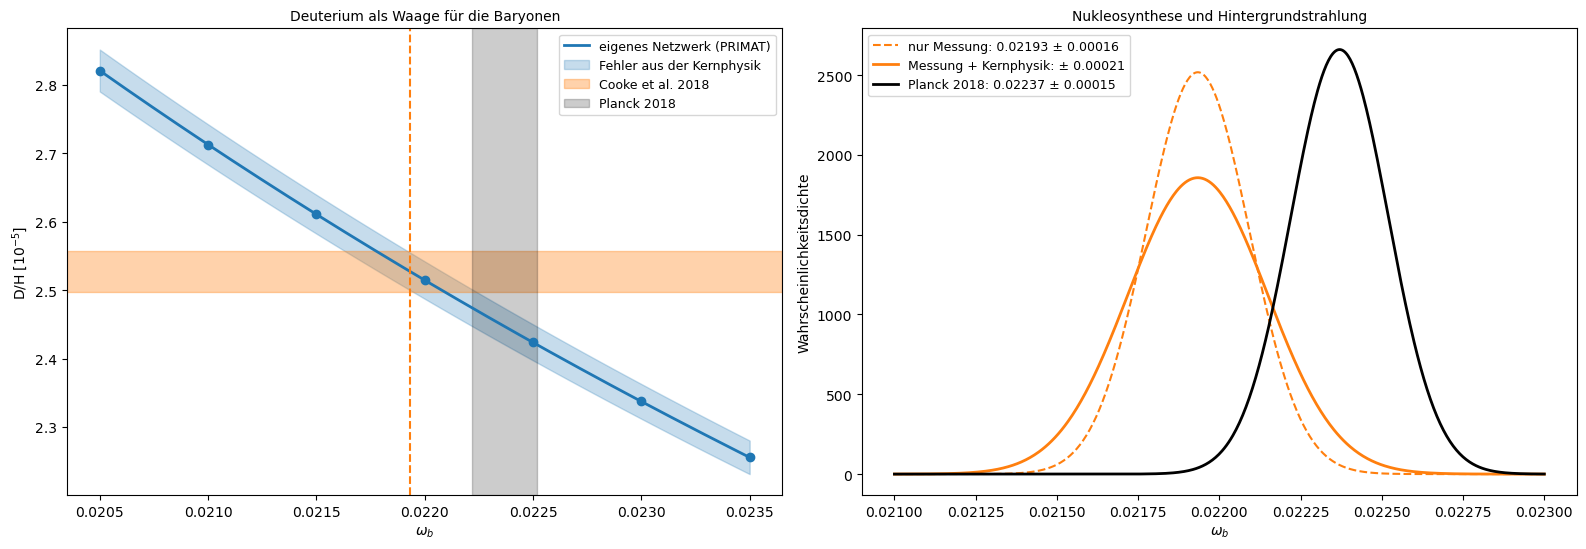

D/H ∝ ω_b^-1.643; D/H bei ω_b von Planck = 2.4467e-05 (+2.0σ gegen Cooke et al.)
ω_b aus D/H = 0.02193 ± 0.00016 (Messung) ± 0.00015 (Kernphysik) = 0.02193 ± 0.00021; η₁₀ = 6.004
gegen Planck: -1.7σ


In [10]:
OB_G = np.linspace(0.0205, 0.0235, 7)
DH_G = np.array([run(o)["DH"] for o in OB_G])
spl = interpolate.CubicSpline(np.log(OB_G), np.log(DH_G))
SLOPE = spl(np.log(PLANCK_OB[0]), 1)
OB_D = np.exp(optimize.brentq(lambda x: spl(x) - np.log(DH_OBS[0]), np.log(OB_G[0]), np.log(OB_G[-1])))
SIG_OBS = OB_D * (DH_OBS[1] / DH_OBS[0]) / abs(SLOPE)
SIG_NUC = OB_D * NUC_ERR["DH"] / abs(SLOPE)
SIG_D = np.hypot(SIG_OBS, SIG_NUC)
DH_PL = np.exp(spl(np.log(PLANCK_OB[0])))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
of = np.linspace(OB_G[0], OB_G[-1], 300)
dh = np.exp(spl(np.log(of)))
ax.plot(of, 1e5 * dh, color="C0", lw=2, label="eigenes Netzwerk (PRIMAT)")
ax.fill_between(of, 1e5 * dh * np.exp(-NUC_ERR["DH"]), 1e5 * dh * np.exp(NUC_ERR["DH"]), color="C0", alpha=0.25, label="Fehler aus der Kernphysik")
ax.plot(OB_G, 1e5 * DH_G, "o", color="C0")
ax.axhspan(1e5 * (DH_OBS[0] - DH_OBS[1]), 1e5 * (DH_OBS[0] + DH_OBS[1]), color="C1", alpha=0.35, label="Cooke et al. 2018")
ax.axvspan(PLANCK_OB[0] - PLANCK_OB[1], PLANCK_OB[0] + PLANCK_OB[1], color="k", alpha=0.2, label="Planck 2018")
ax.axvline(OB_D, color="C1", ls="--")
ax.set_xlabel(r"$\omega_b$")
ax.set_ylabel(r"D/H [$10^{-5}$]")
ax.set_title("Deuterium als Waage für die Baryonen", fontsize=10)
ax.legend(fontsize=9)
og = np.linspace(0.0210, 0.0230, 600)
gauss = lambda m, s: np.exp(-0.5 * ((og - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
ax2.plot(og, gauss(OB_D, SIG_OBS), color="C1", ls="--", label=f"nur Messung: {OB_D:.5f} ± {SIG_OBS:.5f}")
ax2.plot(og, gauss(OB_D, SIG_D), color="C1", lw=2, label=f"Messung + Kernphysik: ± {SIG_D:.5f}")
ax2.plot(og, gauss(*PLANCK_OB), color="k", lw=2, label=f"Planck 2018: {PLANCK_OB[0]} ± {PLANCK_OB[1]}")
ax2.set_xlabel(r"$\omega_b$")
ax2.set_ylabel("Wahrscheinlichkeitsdichte")
ax2.set_title("Nukleosynthese und Hintergrundstrahlung", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"D/H ∝ ω_b^{SLOPE:.3f}; D/H bei ω_b von Planck = {DH_PL:.4e} ({(DH_OBS[0] - DH_PL) / np.hypot(DH_OBS[1], DH_PL * NUC_ERR['DH']):+.1f}σ gegen Cooke et al.)")
print(f"ω_b aus D/H = {OB_D:.5f} ± {SIG_OBS:.5f} (Messung) ± {SIG_NUC:.5f} (Kernphysik) = {OB_D:.5f} ± {SIG_D:.5f}; η₁₀ = {1e10 * omega_to_eta(OB_D):.3f}")
print(f"gegen Planck: {(OB_D - PLANCK_OB[0]) / np.hypot(SIG_D, PLANCK_OB[1]):+.1f}σ")

* Links D/H über $\omega_b$ (Punkte: Netzwerk, Band: Kernphysik), die Messung (orange) und Planck (grau). Die Kurve schneidet die Messung bei $\omega_b$ = 0.02193 (gestrichelt), links von Planck. Rechts die Verteilungen, einmal nur mit dem Fehler der Messung und einmal mit dem der Kernphysik dazu.
* $\omega_b$ = 0.02193 ± 0.00016 (Messung) ± 0.00015 (Kernphysik) = 0.02193 ± 0.00021, also $\eta_{10}$ = 6.00; 1.7σ unter Planck. Umgekehrt sagt das Netzwerk bei $\omega_b$ von Planck D/H = 2.447·10⁻⁵ voraus, 2.0σ unter der Messung. Pitrou et al. (2021) finden dasselbe: 0.02195 ± 0.00022 und eine Spannung von 1.8σ.
* Zur Vorhersage: darunter. Die Messung hat 3.3 % mehr Deuterium als vorhergesagt. Mehr Deuterium heißt weniger Baryonen, die es verbrennen; mit D/H ∝ $\omega_b^{-1.64}$ sind das 2 % weniger $\omega_b$.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-9"></a>

##### *9. Zwei Sätze von Raten*

Wie stark hängt $\omega_b$ aus Deuterium davon ab, welche Kompilation der Kernraten man nimmt, und welche Reaktionen machen den Unterschied? Vorher vorhersagen: Geben höhere Raten der Reaktionen von Deuterium mit Deuterium ein größeres oder kleineres $\omega_b$?

Links steht das Verhältnis NACRE II / PRIMAT für die vier Reaktionen, die Deuterium bilden oder verbrennen, über $T_9$. Grau markiert ist das Fenster, in dem Deuterium verbrennt ($T_9$ ≈ 0.4 bis 1, Schritt 4). Rechts steht $\omega_b$ aus D/H für fünf Varianten: alle Raten von PRIMAT, alle von NACRE II und PRIMAT mit jeweils einer der vier Raten aus NACRE II. Jede Variante wird bei $\omega_b$ aus Schritt 8 gerechnet und mit der Steigung $\text{D/H} \propto \omega_b^{-1.6}$ auf die Messung verschoben.

**Hintergrund & Fachbegriffe:**
- **Ab initio:** Die Raten von d(d,n)³He und d(d,p)t in PRIMAT kommen aus einer Rechnung der Kernstreuung aus den Kräften zwischen Nukleonen (Arai et al. 2011), mit Messungen nur zur Normierung. NACRE II passt eine Funktion direkt an die gemessenen Wirkungsquerschnitte an.
- **S-Faktor:** $S(E) = E\,\sigma(E)\,e^{2\pi\eta_S}$ nimmt die Coulomb-Barriere aus dem Wirkungsquerschnitt heraus, so dass nur eine langsam veränderliche Funktion übrig bleibt, die sich gut zu kleinen Energien fortsetzen lässt; $\eta_S$ ist hier der Sommerfeld-Parameter.

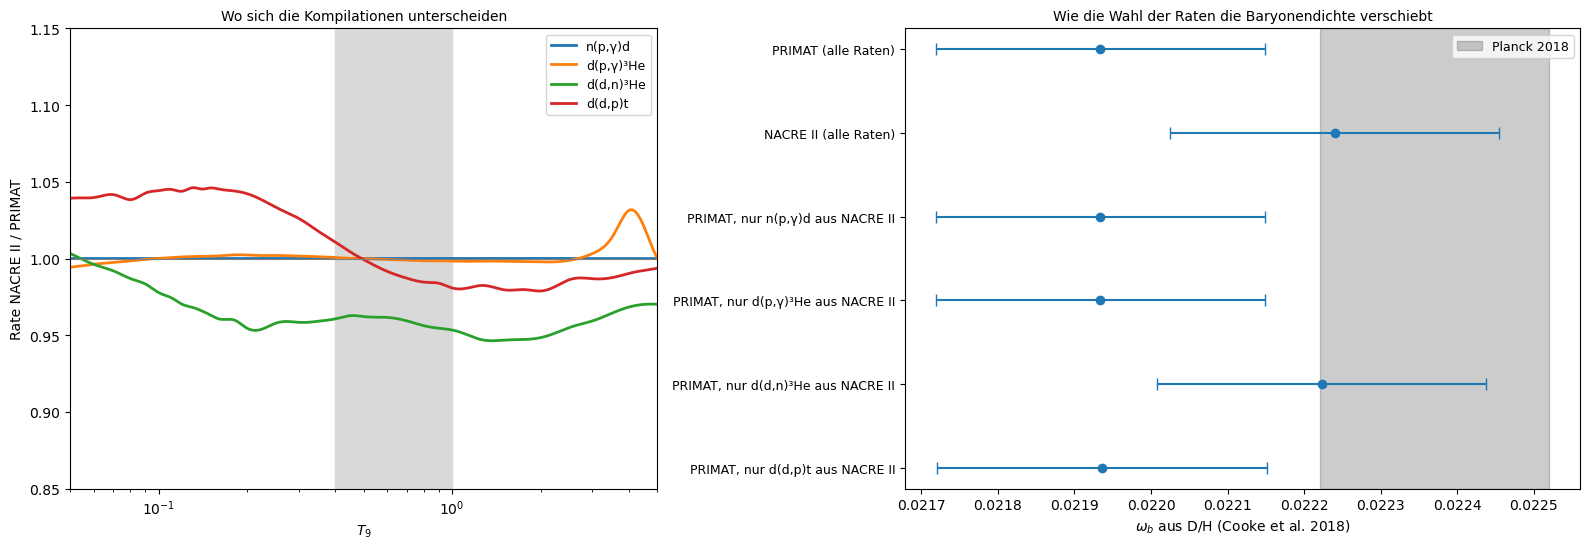

n(p,γ)d     : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 1.0000
d(p,γ)³He   : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 0.9993
d(d,n)³He   : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 0.9594
d(d,p)t     : NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: 0.9923
PRIMAT (alle Raten)                   : ω_b = 0.02193 (-1.7σ gegen Planck)
NACRE II (alle Raten)                 : ω_b = 0.02224 (-0.5σ gegen Planck)
PRIMAT, nur n(p,γ)d aus NACRE II      : ω_b = 0.02193 (-1.7σ gegen Planck)
PRIMAT, nur d(p,γ)³He aus NACRE II    : ω_b = 0.02193 (-1.7σ gegen Planck)
PRIMAT, nur d(d,n)³He aus NACRE II    : ω_b = 0.02222 (-0.6σ gegen Planck)
PRIMAT, nur d(d,p)t aus NACRE II      : ω_b = 0.02194 (-1.7σ gegen Planck)


In [11]:
KEY4 = ["npdg", "dpHe3g", "ddHe3n", "ddtp"]
idx4 = [[n for n, _, _ in REAC].index(k) for k in KEY4]
ref = run(OB_D)["DH"]
VARIANTS = {"PRIMAT (alle Raten)": PRIMAT, "NACRE II (alle Raten)": NACRE}
for k, i in zip(KEY4, idx4):
    mixed = PRIMAT[0].copy()
    mixed[i] = NACRE[0][i]
    VARIANTS[f"PRIMAT, nur {LABEL[k]} aus NACRE II"] = (mixed, PRIMAT[1])
OB_VAR = {lab: OB_D * (run(OB_D, rates=r)["DH"] / ref) ** (1 / abs(SLOPE)) for lab, r in VARIANTS.items()}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
T9 = np.exp(LX)
for k, i, col in zip(KEY4, idx4, ["C0", "C1", "C2", "C3"]):
    ax.semilogx(T9, np.exp(NACRE[0][i] - PRIMAT[0][i]), color=col, lw=2, label=LABEL[k])
ax.axvspan(0.4, 1.0, color="0.85")
ax.axhline(1, color="0.5", lw=0.8)
ax.set_xlim(0.05, 5)
ax.set_ylim(0.85, 1.15)
ax.set_xlabel(r"$T_9$")
ax.set_ylabel("Rate NACRE II / PRIMAT")
ax.set_title("Wo sich die Kompilationen unterscheiden", fontsize=10)
ax.legend(fontsize=9)
labs = list(OB_VAR)
ax2.errorbar([OB_VAR[l] for l in labs], -np.arange(len(labs)), xerr=SIG_D, fmt="o", color="C0", capsize=4)
ax2.axvspan(PLANCK_OB[0] - PLANCK_OB[1], PLANCK_OB[0] + PLANCK_OB[1], color="k", alpha=0.2, label="Planck 2018")
ax2.set_yticks(-np.arange(len(labs)))
ax2.set_yticklabels(labs, fontsize=9)
ax2.set_xlabel(r"$\omega_b$ aus D/H (Cooke et al. 2018)")
ax2.set_title("Wie die Wahl der Raten die Baryonendichte verschiebt", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

w = (T9 > 0.4) & (T9 < 1.0)
for k, i in zip(KEY4, idx4):
    print(f"{LABEL[k]:12s}: NACRE II / PRIMAT im Fenster T₉ = 0.4–1.0: {np.exp(NACRE[0][i] - PRIMAT[0][i])[w].mean():.4f}")
for l in labs:
    print(f"{l:38s}: ω_b = {OB_VAR[l]:.5f} ({(OB_VAR[l] - PLANCK_OB[0]) / np.hypot(SIG_D, PLANCK_OB[1]):+.1f}σ gegen Planck)")

* Links das Verhältnis NACRE II / PRIMAT für die vier Raten. n(p,γ)d und d(p,γ)³He sind im Fenster praktisch gleich (unter 0.1 % Unterschied). d(d,p)t ist in NACRE II um 0.8 % kleiner, d(d,n)³He um 4.1 %. Rechts $\omega_b$ für die fünf Varianten.
* Mit allen Raten aus NACRE II wird $\omega_b$ = 0.02224, nur 0.5σ unter Planck statt 1.7σ. Fast der ganze Unterschied kommt von d(d,n)³He allein (0.02222). Diese 4 % sind fast das Vierfache des Fehlers, den PRIMAT für die Rate angibt (1.1 %). Die beiden Kompilationen widersprechen sich also, und davon hängt ab, ob es eine Spannung gibt.
* Zur Vorhersage: ein kleineres. Höhere Raten verbrennen mehr Deuterium, das Netzwerk sagt bei gleichem $\omega_b$ weniger D/H voraus, und zur Messung passt dann ein kleineres $\omega_b$. PRIMAT hat die höheren Raten und das kleinere $\omega_b$.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-10"></a>

##### *10. Helium und die Zahl der Neutrinoarten*

Wie viele Neutrinoarten (oder andere leichte Teilchen) lassen Helium und Deuterium zusammen zu, und wie stark hängt Helium an der Lebensdauer des Neutrons? Vorher vorhersagen: Um wie viel steigt $Y_p$ mit einer vierten Neutrinoart, verglichen mit dem Fehler der Messung von 0.0034?

Der Code rechnet ein Gitter aus fünf Werten von $\Delta N_\text{eff}$ (−1 bis +1) und sieben Werten von $\omega_b$. Für jedes $N_\text{eff}$ braucht er einen neuen Hintergrund. Dazu kommen zwei Läufe mit $\tau_n$ aus einem Speicherexperiment (UCNτ, 877.75 s) und aus einem Strahlexperiment (887.7 s). Links stehen $Y_p$ über $N_\text{eff}$ bei $\omega_b$ aus Schritt 8, mit der Messung von Aver et al. und den beiden Lebensdauern. Rechts steht die gemeinsame Likelihood von D/H und $Y_p$ in der Ebene von $\omega_b$ und $N_\text{eff}$, mit Planck. Die Fehler sind Messung plus Kernphysik aus Schritt 7. $N_\text{eff}$ ist hier $3.044 + \Delta N_\text{eff}$.

**Hintergrund & Fachbegriffe:**
- **Dunkle Strahlung:** jedes unbekannte leichte Teilchen (sterile Neutrinos, Axionen, Gravitationswellen), das zur Energiedichte beiträgt wie eine zusätzliche Neutrinoart; gemessen als $\Delta N_\text{eff}$.
- **Rätsel der Lebensdauer:** Neutronen, die in magnetischen oder materiellen Fallen gespeichert und gezählt werden, leben 877 bis 879 s. Zählt man die Protonen aus dem Zerfall in einem Neutronenstrahl, kommen etwa 888 s heraus. Der Unterschied ist seit über zehn Jahren ungeklärt.

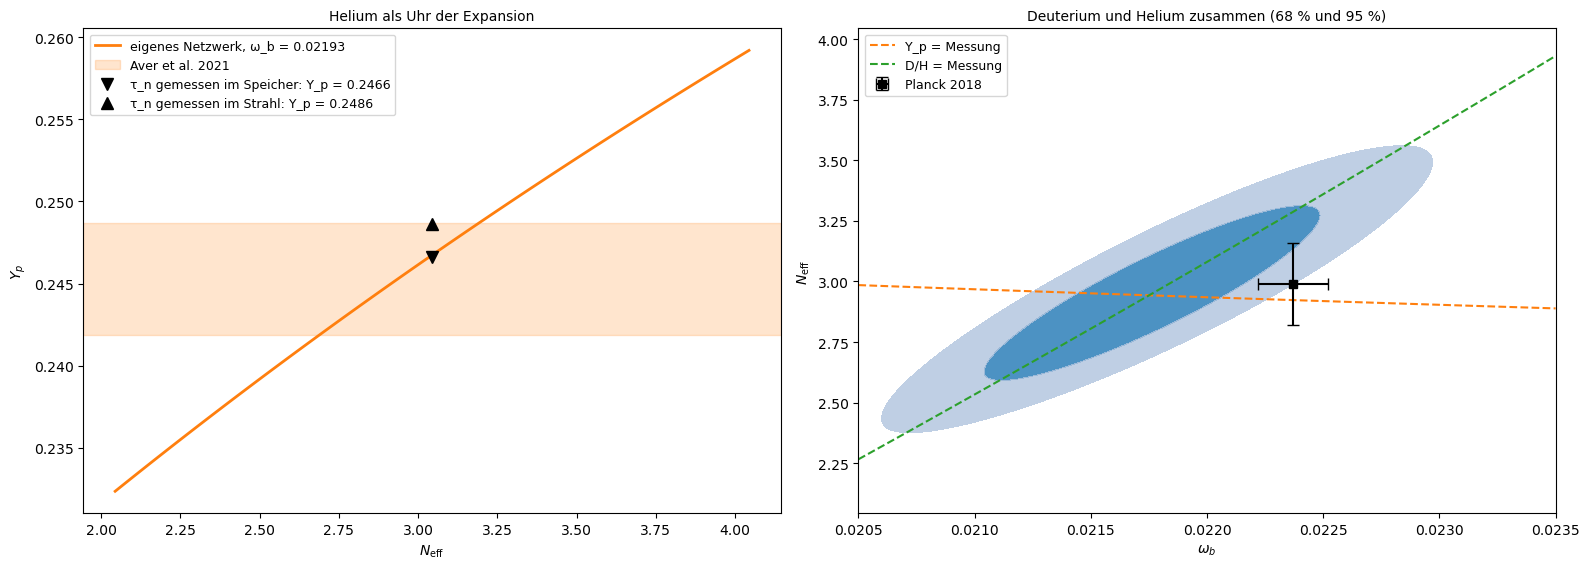

bei ω_b = 0.022: dY_p/dN_eff = 0.0134, d ln(D/H)/dN_eff = 0.136
τ_n: Speicher 877.75 s → Y_p = 0.24660, Strahl 887.7 s → Y_p = 0.24862, Unterschied 0.00202
D/H + Y_p: N_eff = 2.96 ± 0.24, ω_b = 0.02178 ± 0.00047; χ²_min = 0.00; gegen Planck (N_eff 2.99 ± 0.17): -0.1σ


In [12]:
DN = np.array([-1.0, -0.5, 0.0, 0.5, 1.0])
OB_N = np.linspace(0.0205, 0.0235, 7)
GY = np.zeros((len(DN), len(OB_N)))
GD = np.zeros_like(GY)
for i, dn in enumerate(DN):
    for j, ob in enumerate(OB_N):
        r = run(ob, neff=3.0 + dn)
        GY[i, j], GD[i, j] = r["Yp"], r["DH"]
iY = interpolate.RectBivariateSpline(DN, OB_N, GY)
iD = interpolate.RectBivariateSpline(DN, np.log(OB_N), np.log(GD))
YP_TAU = {lab: run(OB_D, tau_n=tau[0])["Yp"] for lab, tau in [("Speicher", TAU_BOTTLE), ("Strahl", TAU_BEAM)]}

dn_f, ob_f = np.linspace(-1, 1, 401), np.linspace(0.0205, 0.0235, 401)
sY = np.hypot(YP_OBS[1], NUC_ERR["Yp"])
sD = np.hypot(DH_OBS[1] / DH_OBS[0], NUC_ERR["DH"])
CHI = ((iY(dn_f, ob_f) - YP_OBS[0]) / sY) ** 2 + ((iD(dn_f, np.log(ob_f)) - np.log(DH_OBS[0])) / sD) ** 2
L = np.exp(-0.5 * (CHI - CHI.min()))
pN, pO = L.sum(1) / L.sum(), L.sum(0) / L.sum()
NEFF = (3.044 + (dn_f * pN).sum(), np.sqrt(((dn_f - (dn_f * pN).sum()) ** 2 * pN).sum()))
OB_DY = ((ob_f * pO).sum(), np.sqrt(((ob_f - (ob_f * pO).sum()) ** 2 * pO).sum()))
DYDN = np.polyfit(DN, GY[:, 3], 1)[0]
DLNDH = np.polyfit(DN, np.log(GD[:, 3]), 1)[0]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))
dd = np.linspace(-1, 1, 100)
ax.plot(3.044 + dd, iY(dd, [OB_D])[:, 0], color="C1", lw=2, label=f"eigenes Netzwerk, ω_b = {OB_D:.5f}")
ax.axhspan(YP_OBS[0] - YP_OBS[1], YP_OBS[0] + YP_OBS[1], color="C1", alpha=0.2, label="Aver et al. 2021")
for (lab, y), m in zip(YP_TAU.items(), ["v", "^"]):
    ax.plot(3.044, y, m, color="k", ms=9, label=f"τ_n gemessen im {lab}: Y_p = {y:.4f}")
ax.set_xlabel(r"$N_\mathrm{eff}$")
ax.set_ylabel(r"$Y_p$")
ax.set_title("Helium als Uhr der Expansion", fontsize=10)
ax.legend(fontsize=9)
lev = [CHI.min() + 2.30, CHI.min() + 6.18]
ax2.contourf(ob_f, 3.044 + dn_f, CHI, levels=[CHI.min(), lev[0], lev[1]], colors=["C0", "lightsteelblue"], alpha=0.8)
ax2.contour(ob_f, 3.044 + dn_f, iY(dn_f, ob_f), levels=[YP_OBS[0]], colors="C1", linestyles="--")
ax2.contour(ob_f, 3.044 + dn_f, iD(dn_f, np.log(ob_f)), levels=[np.log(DH_OBS[0])], colors="C2", linestyles="--")
ax2.errorbar(*PLANCK_OB[:1], PLANCK_NEFF[0], xerr=PLANCK_OB[1], yerr=PLANCK_NEFF[1], fmt="s", color="k", capsize=4, label="Planck 2018")
ax2.plot([], [], color="C1", ls="--", label="Y_p = Messung")
ax2.plot([], [], color="C2", ls="--", label="D/H = Messung")
ax2.set_xlabel(r"$\omega_b$")
ax2.set_ylabel(r"$N_\mathrm{eff}$")
ax2.set_title("Deuterium und Helium zusammen (68 % und 95 %)", fontsize=10)
ax2.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

print(f"bei ω_b = {OB_N[3]}: dY_p/dN_eff = {DYDN:.4f}, d ln(D/H)/dN_eff = {DLNDH:.3f}")
print(f"τ_n: Speicher {TAU_BOTTLE[0]} s → Y_p = {YP_TAU['Speicher']:.5f}, Strahl {TAU_BEAM[0]} s → Y_p = {YP_TAU['Strahl']:.5f}, Unterschied {YP_TAU['Strahl'] - YP_TAU['Speicher']:.5f}")
print(f"D/H + Y_p: N_eff = {NEFF[0]:.2f} ± {NEFF[1]:.2f}, ω_b = {OB_DY[0]:.5f} ± {OB_DY[1]:.5f}; χ²_min = {CHI.min():.2f}; "
      f"gegen Planck (N_eff {PLANCK_NEFF[0]} ± {PLANCK_NEFF[1]}): {(NEFF[0] - PLANCK_NEFF[0]) / np.hypot(NEFF[1], PLANCK_NEFF[1]):+.1f}σ")

* Links $Y_p$ über $N_\text{eff}$ bei $\omega_b$ = 0.02193: eine Gerade mit 0.0134 pro Neutrinoart. Die Messung (Band, ±0.0034) lässt allein etwa ±0.25 in $N_\text{eff}$ zu. Die Dreiecke zeigen $Y_p$ mit $\tau_n$ aus dem Speicherexperiment (0.2466) und aus dem Strahl (0.2486). Der Unterschied von 0.0020 ist 0.6 Messfehler. Rechts die gemeinsame Likelihood: $Y_p$ legt fast nur $N_\text{eff}$ fest (orange, flach). D/H gibt eine schräge Linie (grün), denn mehr $N_\text{eff}$ heißt mehr D/H, was mehr $\omega_b$ ausgleichen muss. Zusammen bleibt eine schmale Ellipse.
* $N_\text{eff}$ = 2.96 ± 0.24 und $\omega_b$ = 0.02178 ± 0.00047. Das passt zu Planck (2.99 ± 0.17) auf 0.1σ. Drei Neutrinoarten passen; eine vierte ($N_\text{eff} \approx 4$) liegt über 4σ daneben. Bei freiem $N_\text{eff}$ wird $\omega_b$ mehr als doppelt so unsicher, weil D/H dann auch von $N_\text{eff}$ abhängt (+14 % pro Neutrinoart).
* Zur Vorhersage: um 0.0134, das sind 4 Messfehler.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-11"></a>

##### *11. Das Lithiumproblem*

Wie weit liegt die Vorhersage für ⁷Li über dem Spite-Plateau, und um welchen Faktor müsste sich eine Kernrate ändern, damit es passt? Vorher vorhersagen: Muss ³He(α,γ)⁷Be kleiner oder größer werden, um weniger Lithium zu bekommen, und ⁷Be(n,p)⁷Li?

Links steht ⁷Li/H über $\omega_b$ aus dem Gitter von Schritt 6 mit dem Spite-Plateau und $\omega_b$ aus Deuterium. Rechts wird bei $\omega_b$ aus Schritt 8 jeweils eine der beiden Reaktionen, die ⁷Be bilden und zerstören, mit Faktoren von 1/10 bis 10 multipliziert. Der Code sucht den Faktor, bei dem ⁷Li/H das Plateau trifft.

**Hintergrund & Fachbegriffe:**
- **Spite-Plateau:** François und Monique Spite fanden 1982, dass alte Halosterne mit weniger als etwa 1/100 der Metalle der Sonne fast alle denselben Lithiumanteil haben; das galt als der Urwert.
- **Erklärungen außerhalb der Kernphysik:** Lithium könnte in den Sternen selbst abgebaut worden sein, durch Diffusion und Mischung unter der Oberfläche. Auch neue Teilchen, die nach der Nukleosynthese zerfallen und ⁷Be zerbrechen, werden diskutiert.

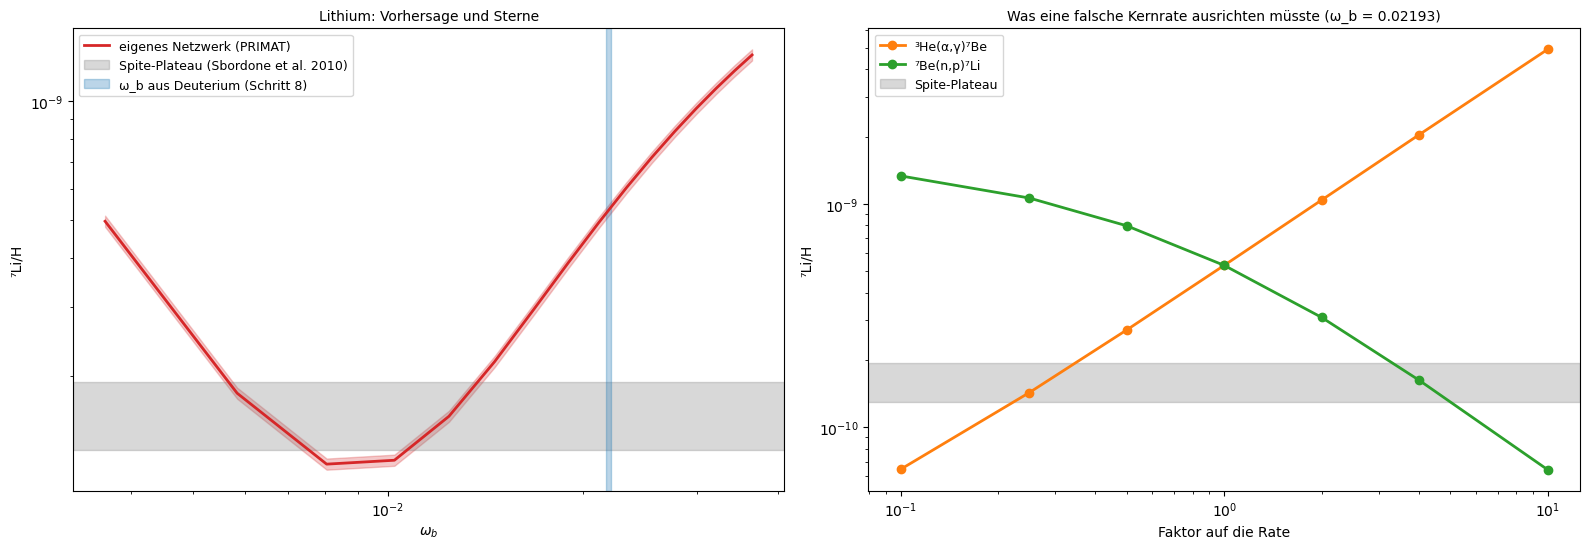

⁷Li/H bei ω_b aus D/H: 5.296e-10 ± 3.3 % (Kernphysik); Spite-Plateau 1.58e-10: Faktor 3.35, 6.0σ
³He(α,γ)⁷Be : ⁷Li/H ∝ Rate^+0.95; nötiger Faktor 0.28, gemessener Fehlerfaktor bei T₉ = 0.5: 1.024
⁷Be(n,p)⁷Li : ⁷Li/H ∝ Rate^-0.66; nötiger Faktor 4.10, gemessener Fehlerfaktor bei T₉ = 0.5: 1.020


In [13]:
LI_D = run(OB_D)["Li7H"]
FACS = np.array([0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 10.0])
LI_FAC = {}
for name in ["He3aBe7g", "Be7nLi7p"]:
    k = [n for n, _, _ in REAC].index(name)
    vals = []
    for f in FACS:
        fac = np.ones((NR, len(LX)))
        fac[k] = f
        vals.append(run(OB_D, fac=fac)["Li7H"])
    LI_FAC[name] = np.array(vals)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.loglog(OB_S, SY["Li7H"], color="C3", lw=2, label="eigenes Netzwerk (PRIMAT)")
ax.fill_between(OB_S, SY["Li7H"] * np.exp(-NUC_ERR["Li7H"]), SY["Li7H"] * np.exp(NUC_ERR["Li7H"]), color="C3", alpha=0.25)
ax.axhspan(LI_OBS[0] * np.exp(-LI_OBS[1]), LI_OBS[0] * np.exp(LI_OBS[1]), color="0.5", alpha=0.3, label="Spite-Plateau (Sbordone et al. 2010)")
ax.axvspan(OB_D - SIG_D, OB_D + SIG_D, color="C0", alpha=0.3, label="ω_b aus Deuterium (Schritt 8)")
ax.set_xlabel(r"$\omega_b$")
ax.set_ylabel("⁷Li/H")
ax.set_title("Lithium: Vorhersage und Sterne", fontsize=10)
ax.legend(fontsize=9)
for (name, v), col in zip(LI_FAC.items(), ["C1", "C2"]):
    ax2.loglog(FACS, v, "o-", color=col, lw=2, label=LABEL[name])
ax2.axhspan(LI_OBS[0] * np.exp(-LI_OBS[1]), LI_OBS[0] * np.exp(LI_OBS[1]), color="0.5", alpha=0.3, label="Spite-Plateau")
ax2.set_xlabel("Faktor auf die Rate")
ax2.set_ylabel("⁷Li/H")
ax2.set_title(f"Was eine falsche Kernrate ausrichten müsste (ω_b = {OB_D:.5f})", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"⁷Li/H bei ω_b aus D/H: {LI_D:.3e} ± {100 * NUC_ERR['Li7H']:.1f} % (Kernphysik); Spite-Plateau {LI_OBS[0]:.2e}: "
      f"Faktor {LI_D / LI_OBS[0]:.2f}, {np.log(LI_D / LI_OBS[0]) / np.hypot(LI_OBS[1], NUC_ERR['Li7H']):.1f}σ")
j08 = np.argmin(abs(LX - np.log(0.5)))
for name, v in LI_FAC.items():
    lv, lf = np.log(v), np.log(FACS)
    need = np.exp(np.interp(np.log(LI_OBS[0]), lv if lv[0] < lv[-1] else lv[::-1], lf if lv[0] < lv[-1] else lf[::-1], left=np.nan, right=np.nan))
    k = [n for n, _, _ in REAC].index(name)
    print(f"{LABEL[name]:12s}: ⁷Li/H ∝ Rate^{np.polyfit(lf, lv, 1)[0]:+.2f}; nötiger Faktor {need:.2f}, gemessener Fehlerfaktor bei T₉ = 0.5: {np.exp(PRIMAT[1][k, j08]):.3f}")

* Links ⁷Li/H über $\omega_b$ mit dem Band aus der Kernphysik, dem Spite-Plateau (grau) und $\omega_b$ aus Deuterium (blau). Bei $\omega_b$ aus Deuterium sagt das Netzwerk ⁷Li/H = 5.30·10⁻¹⁰ voraus, das 3.35-Fache des Plateaus. Mit den Fehlern der Messung (0.086 dex) und der Kernphysik (3.3 %) sind das 6.0σ. Nur in der Senke bei $\omega_b$ ≈ 0.007 bis 0.012 träfe die Kurve das Plateau, und dort wäre D/H vier- bis achtmal so hoch wie gemessen.
* Rechts: ⁷Li/H geht wie Rate^+0.95 für ³He(α,γ)⁷Be und wie Rate^−0.66 für ⁷Be(n,p)⁷Li. Um das Plateau zu treffen, müsste ³He(α,γ)⁷Be auf das 0.28-Fache sinken oder ⁷Be(n,p)⁷Li auf das 4.1-Fache steigen. Gemessen sind beide bei $T_9$ = 0.5 auf 2.4 % und 2.0 %. Eine Lösung in diesen Raten ist damit ausgeschlossen; gesucht wird sie heute eher in den Sternen.
* Zur Vorhersage: ³He(α,γ)⁷Be muss kleiner werden, weil es ⁷Be bildet. ⁷Be(n,p)⁷Li muss größer werden, weil es ⁷Be in ⁷Li umwandelt, das Protonen bei diesen Temperaturen schnell zerstören.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-12"></a>

##### *12. Gegen die veröffentlichten Werte*

Wie passt die eigene Baryonendichte zu den veröffentlichten Werten aus der Nukleosynthese und aus der Hintergrundstrahlung, und was hätte das Notebook cosmology_bao mit dem eigenen Wert ergeben? Vorher vorhersagen: Welcher veröffentlichte Wert liegt am nächsten an PRIMAT, welcher an NACRE II?

Der Code stellt die eigenen Werte (PRIMAT, NACRE II, D/H mit $Y_p$ bei freiem $N_\text{eff}$) neben:
- Cooke et al. (2018), einmal mit der theoretischen und einmal mit der gemessenen Rate von d(p,γ)³He,
- Pitrou et al. (2021),
- Schöneberg (2024), den Wert, den cosmology_bao als Vorgabe genommen hat,
- $\omega_b$ aus den Peakhöhen in cosmology_cmbpeaks,
- Planck.

Er gibt jeweils den Abstand zu Planck aus. Für die inverse Entfernungsleiter gilt $H_0 r_d$ = fest. Mit $r_d \propto \omega_{cb}^{-0.254}\,\omega_b^{-0.128}$ und $\omega_{cb} = \Omega_m h^2$ bei festem $\Omega_m$ folgt $H_0 \propto \omega_b^{0.128/0.493} = \omega_b^{0.26}$. Daraus schätzt der Code, wie sich H₀ aus BAO und Nukleosynthese mit dem eigenen Wert verschöbe.

**Hintergrund & Fachbegriffe:**
- **Inverse Entfernungsleiter:** BAO messen Abstände in Einheiten des Schallhorizonts $r_d$; erst ein Wert für $r_d$ aus $\omega_b$ und $\omega_m$ macht daraus Mpc und damit H₀.
- **$r_d \propto \omega_{cb}^{-0.254}\,\omega_b^{-0.128}$:** Näherung für den Schallhorizont (Aubourg et al. 2015); mehr Baryonen machen den Schall langsamer und den Horizont kleiner.

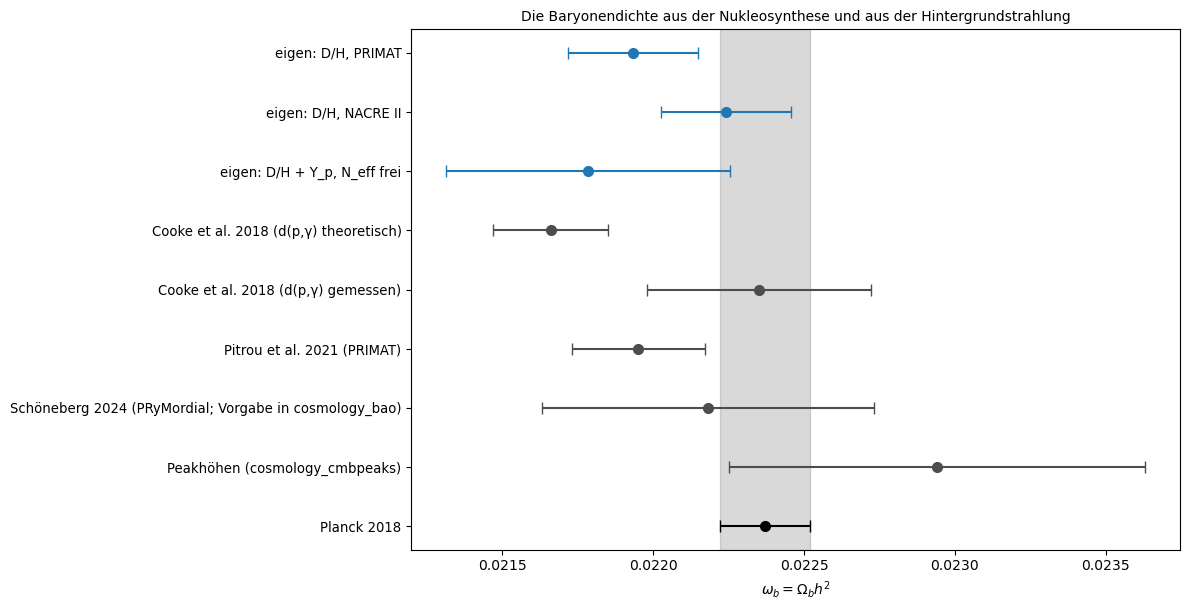

eigen: D/H, PRIMAT                                     : ω_b = 0.02193 ± 0.00021; gegen Planck -1.7σ
eigen: D/H, NACRE II                                   : ω_b = 0.02224 ± 0.00021; gegen Planck -0.5σ
eigen: D/H + Y_p, N_eff frei                           : ω_b = 0.02178 ± 0.00047; gegen Planck -1.2σ
Cooke et al. 2018 (d(p,γ) theoretisch)                 : ω_b = 0.02166 ± 0.00019; gegen Planck -2.9σ
Cooke et al. 2018 (d(p,γ) gemessen)                    : ω_b = 0.02235 ± 0.00037; gegen Planck -0.1σ
Pitrou et al. 2021 (PRIMAT)                            : ω_b = 0.02195 ± 0.00022; gegen Planck -1.6σ
Schöneberg 2024 (PRyMordial; Vorgabe in cosmology_bao) : ω_b = 0.02218 ± 0.00055; gegen Planck -0.3σ
Peakhöhen (cosmology_cmbpeaks)                         : ω_b = 0.02294 ± 0.00069; gegen Planck +0.8σ
H₀ aus BAO + BBN mit dem eigenen ω_b statt 0.02218: etwa 68.33 statt 68.53 km/s/Mpc


In [14]:
OWN = {"eigen: D/H, PRIMAT": (OB_D, SIG_D), "eigen: D/H, NACRE II": (OB_VAR["NACRE II (alle Raten)"], SIG_D),
       "eigen: D/H + Y_p, N_eff frei": OB_DY}
rows = [(k, *v, "C0") for k, v in OWN.items()] + [(k, *v, "0.3") for k, v in OMEGA_LIT.items()] + [("Planck 2018", *PLANCK_OB, "k")]
fig, ax = plt.subplots(figsize=(12, 6.2))
for i, (lab, v, e, col) in enumerate(rows):
    ax.errorbar(v, -i, xerr=e, fmt="o", color=col, ms=7, capsize=4)
ax.axvspan(PLANCK_OB[0] - PLANCK_OB[1], PLANCK_OB[0] + PLANCK_OB[1], color="k", alpha=0.15)
ax.set_yticks(-np.arange(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=9.5)
ax.set_xlabel(r"$\omega_b = \Omega_b h^2$")
ax.set_title("Die Baryonendichte aus der Nukleosynthese und aus der Hintergrundstrahlung", fontsize=10)
plt.tight_layout()
plt.show()

for lab, v, e, _ in rows[:-1]:
    print(f"{lab:55s}: ω_b = {v:.5f} ± {e:.5f}; gegen Planck {(v - PLANCK_OB[0]) / np.hypot(e, PLANCK_OB[1]):+.1f}σ")
H0_BAO = 68.53                                       # cosmology_bao: BAO + BBN mit ω_b = 0.02218
print(f"H₀ aus BAO + BBN mit dem eigenen ω_b statt 0.02218: etwa {H0_BAO * (OB_D / 0.02218) ** (0.128 / 0.493):.2f} statt {H0_BAO} km/s/Mpc")

* Alle Werte von $\omega_b$ mit 1σ-Fehlern: eigene in blau, veröffentlichte in grau, Planck schwarz mit Band. Die eigenen Werte liegen dort, wo die veröffentlichten mit denselben Raten liegen: PRIMAT bei Pitrou et al. (0.02193 gegen 0.02195), NACRE II bei Schöneberg (0.02224 gegen 0.02218) und bei Cooke et al. mit gemessener Rate von d(p,γ) (0.02235).
* Abstände zu Planck: eigene Werte mit PRIMAT −1.7σ, mit NACRE II −0.5σ, mit freiem $N_\text{eff}$ −1.2σ. Cooke et al. mit theoretischer Rate liegen bei −2.9σ, Pitrou et al. bei −1.6σ, Schöneberg bei −0.3σ, die Peakhöhen aus cosmology_cmbpeaks bei +0.8σ. Mit dem eigenen Wert (PRIMAT) statt 0.02218 würde H₀ aus BAO und Nukleosynthese in cosmology_bao nur um 0.2 auf 68.33 km/s/Mpc sinken, weit unter seinem Fehler von 0.60.
* Zur Vorhersage: Pitrou et al. 2021 neben PRIMAT (gleiche Raten), Schöneberg 2024 neben NACRE II (gleicher Code, ähnliche Raten). Ob Nukleosynthese und Hintergrundstrahlung um 1.7σ auseinanderliegen oder gar nicht, entscheiden vor allem die Raten von d(d,n)³He und, bei Cooke et al., von d(p,γ)³He.

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-08 (eigenes Netzwerk mit 12 Reaktionen und Born-Raten plus Korrekturen nach Pitrou et al. 2018; Raten PRIMAT und NACRE II aus PRyMordial; $\tau_n$ = 878.4 s):

- **Die ersten Minuten:** Die Neutronen frieren bei 0.66 MeV (1.7 s) mit $X_n$ = 0.21 aus. Bis Helium bei 0.072 MeV (247 s) entsteht, bleiben 0.12 übrig, etwa zur Hälfte durch Zerfall und zur Hälfte durch schwache Reaktionen nach dem Ausfrieren. Die Neutrinos sind am Ende um den Faktor $(4/11)^{1/3}$ kälter als die Photonen.
- **Prüfung:** Gegen PRIMAT 2021 stimmen $Y_p$ auf 0.00006, D/H und ³He/H auf 0.03 % und ⁷Li/H auf 1.5 %. Gegen PRyMordial stimmen $Y_p$ auf 0.0003 und D/H auf 0.75 %, für $\omega_b$ = 0.020 bis 0.024 und $\Delta N_\text{eff}$ = −1 bis +1.
- **Fehler aus der Kernphysik:** D/H 1.1 %, vor allem durch d(p,γ)³He, d(d,n)³He und d(d,p)t; ⁷Li/H 3.3 %; $Y_p$ 0.0001.
- **Baryonendichte aus Deuterium:** **$\omega_b$ = 0.02193 ± 0.00021** mit PRIMAT, 1.7σ unter Planck (0.02237 ± 0.00015), wie bei Pitrou et al. (2021). Mit NACRE II sind es 0.02224, nur 0.5σ unter Planck. Den Unterschied macht fast allein d(d,n)³He: Die beiden Kompilationen unterscheiden sich dort um 4 %, bei einem angegebenen Fehler von 1.1 %.
- **Neutrinoarten:** Aus D/H und $Y_p$ zusammen folgt **$N_\text{eff}$ = 2.96 ± 0.24**, verträglich mit drei Neutrinoarten und mit Planck. Die Unsicherheit der Lebensdauer des Neutrons (Speicher gegen Strahl) verschiebt $Y_p$ um 0.002.
- **Lithium:** Die Vorhersage liegt beim 3.35-Fachen des Spite-Plateaus (6σ). Dafür müsste ³He(α,γ)⁷Be um den Faktor 0.28 oder ⁷Be(n,p)⁷Li um den Faktor 4.1 falsch sein; gemessen sind beide auf 2 bis 3 %.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und das Notebook neu ausführen:

1. **Die Lebensdauer aus dem Strahl:** `TAU_N = (887.7, 2.3)`. *(Vorhersage: Mehr Neutronen überleben; $Y_p$ bei Planck steigt um 0.0019 auf 0.2488. D/H steigt nur wenig, und $\omega_b$ aus Deuterium wird 0.02199 statt 0.02193. Weil $Y_p$ höher ist, braucht man weniger Expansion: $N_\text{eff}$ = 2.83 ± 0.23.)*
2. **Ohne Korrekturen zur Born-Näherung:** in der Code-Zelle `BORN_CORR = dict(Yp=0.0, DH=1.0, He3H=1.0, Li7H=1.0)`. *(Vorhersage: D/H wird um 1.5 % kleiner vorhergesagt; zur Messung passt dann ein kleineres $\omega_b$, 0.02174, 2.4σ unter Planck. $Y_p$ fällt um 0.0045, und das muss eine schnellere Expansion ausgleichen: $N_\text{eff}$ = 3.28 statt 2.96.)*
3. **Der Mittelwert der Particle Data Group:** `DH_OBS = (2.547e-5, 0.029e-5)`, das gewichtete Mittel von elf Systemen (PDG 2024). *(Vorhersage: 0.8 % mehr Deuterium geben 0.5 % weniger Baryonen, $\omega_b$ = 0.02183 ± 0.00021, 2.1σ unter Planck. $N_\text{eff}$ ändert sich kaum, denn es hängt an $Y_p$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum sind die Neutrinos am Ende kälter als die Photonen?</summary>

Sie entkoppeln bei etwa 2 MeV, bevor Elektronen und Positronen zerstrahlen. Die Entropie der Paare geht nur an die Photonen, und aus ihrer Erhaltung folgt $T_\nu/T = (4/11)^{1/3}$.
</details>

<details><summary>2. Warum gibt es überhaupt Neutronen, wenn das Gleichgewicht bei 0.1 MeV fast keine mehr erlaubt?</summary>

Die schwachen Reaktionen werden langsamer als die Expansion und frieren bei etwa 0.7 MeV aus. Danach folgt das Verhältnis nicht mehr $e^{-Q/T}$, und die Neutronen zerfallen nur noch langsam mit $\tau_n$ = 878 s.
</details>

<details><summary>3. Was legt die Normierung der schwachen Raten fest?</summary>

Die gemessene Lebensdauer des Neutrons. Alle Reaktionen $n \leftrightarrow p$ haben dasselbe Matrixelement; der Zerfall im Vakuum eicht es.
</details>

<details><summary>4. Warum entsteht Deuterium erst bei 0.07 MeV, obwohl es mit 2.2 MeV gebunden ist?</summary>

Auf jedes Baryon kommen über eine Milliarde Photonen. Schon der kleine Teil im Wien-Ausläufer mit mehr als 2.2 MeV reicht, um jedes Deuteron sofort zu zerbrechen, bis $kT$ etwa ein Dreißigstel der Bindungsenergie ist.
</details>

<details><summary>5. Warum ist $Y_p \approx 2 X_n$?</summary>

Helium-4 enthält zwei Neutronen und zwei Protonen und ist der am stärksten gebundene leichte Kern. Fast jedes Neutron endet dort; der Massenanteil des Heliums ist dann doppelt so groß wie der Anteil der Neutronen.
</details>

<details><summary>6. Warum ist Deuterium ein so gutes Maß für die Baryonendichte, Helium aber nicht?</summary>

Deuterium wird verbrannt, und wie gründlich, hängt von der Dichte ab: D/H ∝ $\omega_b^{-1.6}$. Helium hängt fast nur am Anteil der Neutronen, und der wird von den schwachen Reaktionen und der Expansion bestimmt, kaum von der Dichte.
</details>

<details><summary>7. Wie folgt die Rückreaktion aus der Hinreaktion?</summary>

Aus dem detaillierten Gleichgewicht: Im thermischen Gleichgewicht müssen beide Richtungen gleich oft ablaufen. Das Verhältnis der Raten ist dann durch Spins, Massen und den Energiegewinn $Q$ festgelegt (Saha-Faktor mal $e^{-Q/kT}$).
</details>

<details><summary>8. Warum ist das Netzwerk steif, und was folgt daraus für die Numerik?</summary>

Die Photodissoziation des Deuterons läuft anfangs mit Raten von über $10^{14}$ pro Sekunde, die Expansion mit etwa 1 pro Sekunde. Ein explizites Verfahren müsste winzige Schritte machen; ein implizites (Radau) mit Jacobi-Matrix kann den langsamen Verlauf mit großen Schritten verfolgen. Starten muss man im Gleichgewicht, sonst scheitert schon der erste Schritt.
</details>

<details><summary>9. Welche Reaktionen bestimmen den Fehler von D/H?</summary>

d(p,γ)³He, d(d,n)³He und d(d,p)t, die drei Reaktionen, die Deuterium verbrennen. Zusammen geben sie etwa 1.1 % in D/H, fast so viel wie der Fehler der Messung.
</details>

<details><summary>10. Warum gibt NACRE II ein größeres $\omega_b$ als PRIMAT?</summary>

NACRE II hat für d(d,n)³He eine um 4 % kleinere Rate. Dann verbrennt weniger Deuterium, das Netzwerk sagt bei gleichem $\omega_b$ mehr D/H voraus, und zur Messung passt ein größeres $\omega_b$.
</details>

<details><summary>11. Wie misst Helium die Zahl der Neutrinoarten?</summary>

Mehr leichte Teilchen heißt mehr Energiedichte und schnellere Expansion. Die Neutronen frieren früher aus, bei höherem $X_n$, und es bleibt weniger Zeit für den Zerfall. $Y_p$ steigt um 0.0134 pro zusätzlicher Neutrinoart.
</details>

<details><summary>12. Warum braucht man für $N_\text{eff}$ Deuterium und Helium zusammen?</summary>

Beide hängen von $\omega_b$ und $N_\text{eff}$ ab, aber in verschiedenen Richtungen: Helium fast nur von $N_\text{eff}$, Deuterium von beiden. Erst zusammen legen sie beide Größen fest.
</details>

<details><summary>13. Was ist das Lithiumproblem?</summary>

Bei der Baryonendichte aus Deuterium und aus der Hintergrundstrahlung sagt die Nukleosynthese etwa dreimal so viel ⁷Li voraus, wie alte Halosterne zeigen. Die Kernraten müssten dafür um Faktoren 3 bis 4 falsch sein, gemessen sind sie auf wenige Prozent.
</details>

<details><summary>14. Warum ist Deuterium aus fernen Gaswolken ein Urwert, das heutige Deuterium aber nicht?</summary>

Sterne verbrennen Deuterium und erzeugen keines. Gas mit fast keinen schweren Elementen war noch kaum in Sternen und hat den ursprünglichen Wert bewahrt.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Die Korrekturen selbst rechnen:** Strahlungskorrekturen, endliche Masse der Nukleonen und die Entkopplung der Neutrinos direkt in die schwachen Raten einbauen, statt sie als feste Zahlen aus Pitrou et al. zu übernehmen; das macht $Y_p$ für jedes $N_\text{eff}$ und $\tau_n$ richtig.
- **Ein größeres Netzwerk:** etwa 60 Reaktionen mit ⁶Li, ⁸Li und ⁸B, damit ⁶Li und Spuren schwererer Kerne vorhergesagt werden und ⁷Li auf unter 1 % stimmt.
- **Monte Carlo über alle Raten:** eine Kette in $\omega_b$, $N_\text{eff}$ und allen Raten zugleich, wie in PRyMordial. Für die Reaktionen d + d gehört die Abweichung zwischen Theorie und Messung als zusätzlicher Fehler hinein (Schöneberg 2024).
- **Mit der Hintergrundstrahlung kombinieren:** Nukleosynthese und Planck gemeinsam fitten, mit $Y_p$ als Vorgabe für das Spektrum der Hintergrundstrahlung, die selbst empfindlich auf Helium ist.
- **Neue Messungen:** die Reaktionen d(d,n)³He und d(d,p)t bei den Energien der Nukleosynthese genauer messen; mehr Systeme für D/H mit den großen Teleskopen der nächsten Generation (ELT); die Lebensdauer des Neutrons klären.

#### **Referenzen**

- Alpher, R. A., Bethe, H. & Gamow, G. (1948): *The origin of chemical elements*, Phys. Rev. 73, 803.
- Wagoner, R. V., Fowler, W. A. & Hoyle, F. (1967): *On the synthesis of elements at very high temperatures*, ApJ 148, 3.
- Kolb, E. W. & Turner, M. S. (1990): *The Early Universe*, Addison-Wesley (Kap. 3 und 4: Thermodynamik und Nukleosynthese).
- Bernstein, J., Brown, L. S. & Feinberg, G. (1989): *Cosmological helium production simplified*, Rev. Mod. Phys. 61, 25 (schwache Raten in Born-Näherung).
- Pitrou, C., Coc, A., Uzan, J.-P. & Vangioni, E. (2018): *Precision big bang nucleosynthesis with improved Helium-4 predictions*, Phys. Rep. 754, 1 (Tabelle V); arXiv:1801.08023.
- Pitrou, C., Coc, A., Uzan, J.-P. & Vangioni, E. (2021): *A new tension in the cosmological model from primordial deuterium?*, MNRAS 502, 2474 (Tabelle 2); arXiv:2011.11320.
- Burns, A.-K., Tait, T. M. P. & Valli, M. (2024): *PRyMordial: the first three minutes, within and beyond the standard model*, Eur. Phys. J. C 84, 86; arXiv:2307.07061.
- Schöneberg, N. (2024): *The 2024 BBN baryon abundance update*, arXiv:2401.15054.
- Xu, Y. et al. (2013): *NACRE II: an update of the NACRE compilation of charged-particle-induced thermonuclear reaction rates for nuclei with mass number A < 16*, Nucl. Phys. A 918, 61.
- Mossa, V. et al. (LUNA) (2020): *The baryon density of the Universe from an improved rate of deuterium burning*, Nature 587, 210.
- Arai, K., Aoyama, S., Suzuki, Y., Descouvemont, P. & Baye, D. (2011): *Tensor force manifestations in ab initio study of the ²H(d,γ)⁴He, ²H(d,p)³H, and ²H(d,n)³He reactions*, Phys. Rev. Lett. 107, 132502.
- Cooke, R. J., Pettini, M. & Steidel, C. C. (2018): *One percent determination of the primordial deuterium abundance*, ApJ 855, 102.
- Aver, E. et al. (2021): *Improving helium abundance determinations with Leo P as a case study*, JCAP 03, 027.
- Sbordone, L. et al. (2010): *The metal-poor end of the Spite plateau. I. Stellar parameters, metallicities, and lithium abundances*, A&A 522, A26.
- Bania, T. M., Rood, R. T. & Balser, D. S. (2002): *The cosmological density of baryons from observations of ³He⁺ in the Milky Way*, Nature 415, 54.
- Gonzalez, F. M. et al. (UCNτ) (2021): *Improved neutron lifetime measurement with UCNτ*, Phys. Rev. Lett. 127, 162501.
- Yue, A. T. et al. (2013): *Improved determination of the neutron lifetime*, Phys. Rev. Lett. 111, 222501.
- Particle Data Group, Fields, B. D., Molaro, P. & Sarkar, S. (2024): *Big-Bang Nucleosynthesis*, in Review of Particle Physics, Phys. Rev. D 110, 030001 (Kap. 24).
- Aubourg, É. et al. (2015): *Cosmological implications of baryon acoustic oscillation measurements*, Phys. Rev. D 92, 123516.
- Planck Collaboration (2020): *Planck 2018 results. VI. Cosmological parameters*, A&A 641, A6.